# 🧬 GlucoProfile — Classification supervisée des profils patients

## Objectif[¶](http://localhost:8888/lab#Objectif)

Ce notebook constitue la troisième étape du projet **GlucoProfile**.

À partir des profils patients identifiés lors de l'étape de clustering, nous allons maintenant construire un système de **classification supervisée** capable de reproduire l'appartenance d'un patient à un cluster.

Le dataset utilisé contient les caractéristiques cliniques suivantes :

- Pregnancies
- Glucose
- BloodPressure
- SkinThickness
- Insulin
- BMI
- DiabetesPedigreeFunction
- Age

Le modèle devra prédire :

- `Cluster 0` → profil classé dans le premier groupe ;
- `Cluster 1` → profil classé dans le second groupe.

> **Important :** la variable `Cluster` provient du clustering non supervisé réalisé précédemment.
> Le modèle de classification n'apprend donc pas à prédire un diagnostic médical réel de diabète.
> Il apprend à **reproduire les décisions du clustering** à partir des caractéristiques cliniques.

## Objectifs du notebook

Nous allons :

1. préparer les données pour la classification ;
2. définir `X` et `y` ;
3. séparer les données en entraînement et test ;
4. comprendre le fonctionnement des principaux modèles de classification ;
5. comparer plusieurs stratégies de normalisation ;
6. gérer le déséquilibre éventuel des classes ;
7. comparer plusieurs classifieurs ;
8. évaluer leurs performances avec plusieurs métriques ;
9. optimiser les meilleurs modèles avec `GridSearchCV` ou `RandomizedSearchCV` ;
10. analyser leurs performances et leurs erreurs ;
11. sélectionner le modèle final ;
12. construire une pipeline complète ;

## Deux représentations des données

| **Dataset** | **Contenu** | **Usage** |
|---|---|---|
| `df_clean` | Données cliniques nettoyées et imputées dans les unités originales | Variables d'entrée du classifieur |
| `df_transformed` | Données avec transformations log/sqrt | Référence et cohérence avec le preprocessing précédent |
| `df_clustered` | Données cliniques + `Cluster` + `risk_category` | Construction de la cible `y` |


> **Rappel important :** `risk_category` ne sera jamais utilisée comme variable d'entrée du modèle.
> Elle dépend directement de `Cluster` et provoquerait une fuite d'information (*target leakage*).

## 2. Imports

Nous importons ici les bibliothèques nécessaires pour :

- manipuler les données ;
- effectuer le prétraitement ;
- construire les modèles de classification ;
- gérer le déséquilibre des classes ;
- évaluer les modèles ;
- construire les pipelines ;
- sauvegarder les modèles.

Les modèles seront introduits progressivement dans les sections théoriques avant leur utilisation dans les expérimentations.

In [18]:
from pathlib import Path
import json
import platform
from importlib import metadata

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline as SklearnPipeline
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV,
    RandomizedSearchCV,
)

from sklearn.preprocessing import (
    StandardScaler,
    RobustScaler,
    MinMaxScaler,
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
)

from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_auc_score,
)

from sklearn.inspection import permutation_importance

from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

RANDOM_STATE = 42

## 3. Configuration, chemins et constantes

Cette section centralise les paramètres du notebook afin d'éviter les valeurs écrites en dur dans plusieurs cellules.

Cette organisation facilite :

- la reproductibilité ;
- les changements de configuration ;
- le passage ultérieur vers un script de training ;
- le tracking avec MLflow.

### Convention

Le dataset contenant les labels issus du clustering sera notre source principale pour la classification :

`data/processed/diabetes_clustered.csv`

In [19]:
def find_project_root() -> Path:
    current = Path.cwd().resolve()

    candidates = [
        current,
        current.parent,
        current.parent.parent,
    ]

    for candidate in candidates:
        expected_file = candidate / "data" / "processed" / "diabetes_clustered.csv"

        if expected_file.exists():
            return candidate

    raise FileNotFoundError(
        "Impossible de trouver la racine du projet. "
        "Vérifiez que diabetes_clustered.csv existe dans data/processed/."
    )


PROJECT_ROOT = find_project_root()

DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"

CLEANED_DATA_PATH = PROCESSED_DIR / "diabetes_cleaned.csv"
TRANSFORMED_DATA_PATH = PROCESSED_DIR / "diabetes_transformed.csv"
CLUSTERED_DATA_PATH = PROCESSED_DIR / "diabetes_clustered.csv"


FEATURES = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
]

TARGET = "Cluster"
RISK_COLUMN = "risk_category"


TEST_SIZE = 0.20

CLASSIFICATION_FEATURES = FEATURES.copy()

CLASS_LABELS = {
    0: "Cluster 0",
    1: "Cluster 1",
}

POSITIVE_CLASS = 1


SCALERS = {
    "StandardScaler": StandardScaler(),
    "RobustScaler": RobustScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "NoScaling": "passthrough",
}


SAMPLERS = {
    "None": "passthrough",
    "RandomOverSampler": RandomOverSampler(
        random_state=RANDOM_STATE
    ),
    "RandomUnderSampler": RandomUnderSampler(
        random_state=RANDOM_STATE
    ),
    "SMOTE": SMOTE(
        random_state=RANDOM_STATE
    ),
}


CLASSIFIERS = {
    "LogisticRegression": LogisticRegression(
        random_state=RANDOM_STATE,
        max_iter=5000,
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
    ),

    "SVM": SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        random_state=RANDOM_STATE,
    ),

    "DecisionTree": DecisionTreeClassifier(
        random_state=RANDOM_STATE,
    ),

    "RandomForest": RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_estimators=200,
        n_jobs=-1,
    ),

    "ExtraTrees": ExtraTreesClassifier(
        random_state=RANDOM_STATE,
        n_estimators=200,
        n_jobs=-1,
    ),

    "HistGradientBoosting": HistGradientBoostingClassifier(
        random_state=RANDOM_STATE,
    ),
}


CV_SPLITS = 5

CV = StratifiedKFold(
    n_splits=CV_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

FINAL_PIPELINE_PATH = MODELS_DIR / "classification_final_pipeline.joblib"
FINAL_METADATA_PATH = MODELS_DIR / "classification_final_metadata.json"
BENCHMARK_REPORT_PATH = REPORTS_DIR / "classification_benchmark.csv"

## 4. Chargement des données et vérifications

Nous rechargeons les données produites par les étapes précédentes.

### Pourquoi charger plusieurs datasets ?

`df_clean` contient les variables dans leurs unités cliniques originales.

`df_transformed` contient les transformations utilisées pendant le clustering.

`df_clustered` contient en plus :

- `Cluster` : la classe créée par K-Means ;
- `risk_category` : l'interprétation métier du cluster.

### Vérifications effectuées

Nous allons vérifier :

- les dimensions ;
- les colonnes ;
- les valeurs manquantes ;
- les valeurs infinies ;
- les doublons ;
- les classes présentes dans `Cluster` ;
- la cohérence entre les datasets.

Cette étape sert à éviter de lancer des expériences sur un dataset incorrect.

In [20]:
for path in (
    CLEANED_DATA_PATH,
    TRANSFORMED_DATA_PATH,
    CLUSTERED_DATA_PATH,
):
    if not path.exists():
        raise FileNotFoundError(f"Fichier introuvable : {path}")


df_clean = pd.read_csv(CLEANED_DATA_PATH)
df_transformed = pd.read_csv(TRANSFORMED_DATA_PATH)
df_clustered = pd.read_csv(CLUSTERED_DATA_PATH)

assert list(df_clean.columns) == FEATURES, (
    "Colonnes inattendues dans df_clean"
)

assert list(df_transformed.columns) == FEATURES, (
    "Colonnes inattendues dans df_transformed"
)

expected_clustered_columns = FEATURES + [
    TARGET,
    RISK_COLUMN,
]

assert list(df_clustered.columns) == expected_clustered_columns, (
    "Colonnes inattendues dans df_clustered"
)


assert df_clean.shape[0] == df_transformed.shape[0], (
    "df_clean et df_transformed n'ont pas le même nombre de lignes"
)

assert df_clean.shape[0] == df_clustered.shape[0], (
    "df_clean et df_clustered n'ont pas le même nombre de lignes"
)


assert df_clean.isna().sum().sum() == 0, (
    "df_clean contient encore des valeurs manquantes"
)

assert df_transformed.isna().sum().sum() == 0, (
    "df_transformed contient encore des valeurs manquantes"
)

assert df_clustered.isna().sum().sum() == 0, (
    "df_clustered contient encore des valeurs manquantes"
)


assert np.isfinite(
    df_clean[FEATURES].to_numpy()
).all()

assert np.isfinite(
    df_transformed[FEATURES].to_numpy()
).all()


df_clustered[TARGET] = df_clustered[TARGET].astype(int)

unique_clusters = sorted(
    df_clustered[TARGET].unique().tolist()
)

assert set(unique_clusters).issubset({0, 1}), (
    f"Labels Cluster inattendus : {unique_clusters}"
)

assert len(unique_clusters) == 2, (
    f"La classification binaire nécessite exactement 2 classes : "
    f"{unique_clusters}"
)


assert df_clustered[RISK_COLUMN].notna().all()

risk_mapping = (
    df_clustered[[TARGET, RISK_COLUMN]]
    .drop_duplicates()
    .sort_values(TARGET)
)

print("Projet : ", PROJECT_ROOT)
print("df_clean : ", df_clean.shape)
print("df_transformed : ", df_transformed.shape)
print("df_clustered : ", df_clustered.shape)
print("Clusters présents : ", unique_clusters)
print(
    "Répartition des clusters :\n",
    df_clustered[TARGET].value_counts().sort_index(),
)

display(risk_mapping)

Projet :  /home/badr-eddine-slaoui/Documents/GlucoProfile
df_clean :  (768, 8)
df_transformed :  (768, 8)
df_clustered :  (768, 10)
Clusters présents :  [0, 1]
Répartition des clusters :
 Cluster
0    382
1    386
Name: count, dtype: int64


,Cluster,risk_category
1,0,Risque Faible
0,1,Risque Élevé


## 5. Définition de `X` et `y`

En classification supervisée :

- `X` représente les **variables explicatives** ;
- `y` représente la **variable cible**.

Ici :

\[
X = \text{caractéristiques cliniques du patient}
\]

\[
y = \text{Cluster}
\]

### Variables utilisées dans `X`

Nous utilisons les caractéristiques cliniques :

- Pregnancies
- Glucose
- BloodPressure
- SkinThickness
- Insulin
- BMI
- DiabetesPedigreeFunction
- Age

### Variable cible

```text
Cluster
```

### Variable explicitement exclue

```text
risk_category
```

### Pourquoi ?

Parce que risk_category est créée à partir de Cluster.

### Par exemple :

```text
Cluster 1 → Risque Élevé
Cluster 0 → Risque Faible
```

Utiliser risk_category comme entrée reviendrait donc à donner indirectement la réponse au modèle.

C'est ce qu'on appelle une fuite d'information, ou target leakage.

> Le modèle doit apprendre à prédire Cluster uniquement à partir des caractéristiques du patient.

In [21]:
X = df_clustered[CLASSIFICATION_FEATURES].copy()
y = df_clustered[TARGET].copy()

assert TARGET not in X.columns
assert RISK_COLUMN not in X.columns

assert len(X) == len(y)

assert X.isna().sum().sum() == 0
assert np.isfinite(X.to_numpy()).all()

assert y.isna().sum() == 0
assert set(y.unique()).issubset({0, 1})

CLASSIFICATION_FEATURES_COUNT = len(CLASSIFICATION_FEATURES)

print(
    "Nombre de features :",
    CLASSIFICATION_FEATURES_COUNT,
)

print(
    "Features utilisées :",
    ", ".join(CLASSIFICATION_FEATURES),
)

print(
    "Target :",
    TARGET,
)

Nombre de features : 8
Features utilisées : Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, DiabetesPedigreeFunction, Age
Target : Cluster


## 6. Séparation des données : entraînement et test

Nous séparons le dataset en deux parties :

### Ensemble d'entraînement

Il est utilisé pour :

- apprendre les paramètres du modèle ;
- ajuster le scaler ;
- effectuer le sur-échantillonnage ou sous-échantillonnage ;
- effectuer la validation croisée ;
- optimiser les hyperparamètres.

### Ensemble de test

Il reste totalement indépendant pendant l'entraînement.

Il sert à mesurer la performance finale du modèle.

---

### Pourquoi utiliser `stratify=y` ?

`stratify=y` conserve approximativement la même proportion de chaque classe dans :

- l'ensemble d'entraînement ;
- l'ensemble de test.

Exemple :

```text
Dataset
Cluster 0 : 70 %
Cluster 1 : 30 %
```

Après une séparation stratifiée :

```text
Train
Cluster 0 : ≈ 70 %
Cluster 1 : ≈ 30 %

Test
Cluster 0 : ≈ 70 %
Cluster 1 : ≈ 30 %
```
C'est particulièrement important lorsque les classes sont déséquilibrées.

### Pourquoi 80 / 20 ?

Nous utilisons :

- 80 % pour l'apprentissage ;
- 20 % pour le test final.

Le test reste donc suffisamment grand pour fournir une estimation utile des performances.

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

assert len(X_train) + len(X_test) == len(X)
assert len(y_train) + len(y_test) == len(y)

assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)

assert set(y_train.unique()) == set(y_test.unique())

train_distribution = (
    y_train
    .value_counts(normalize=True)
    .sort_index()
    .rename("proportion")
)

test_distribution = (
    y_test
    .value_counts(normalize=True)
    .sort_index()
    .rename("proportion")
)

split_distribution = pd.DataFrame({
    "train": y_train.value_counts().sort_index(),
    "test": y_test.value_counts().sort_index(),
})

split_distribution["train_pct"] = (
    split_distribution["train"]
    / len(y_train)
    * 100
)

split_distribution["test_pct"] = (
    split_distribution["test"]
    / len(y_test)
    * 100
)

display(split_distribution)

,train,test,train_pct,test_pct
Cluster,,,,
0,305,77,49.674267,50.0
1,309,77,50.325733,50.0


## 7. Qu'est-ce que la classification supervisée ?

La **classification supervisée** consiste à apprendre une fonction permettant de prédire une classe à partir de données dont la classe est déjà connue.

On possède :

```text
X → caractéristiques du patient
y → classe connue
```

Le modèle cherche une relation :

$$ f(X) \rightarrow y $$

Dans notre projet :

```
Patient
   ↓
Glucose
BloodPressure
BMI
Age
...
   ↓
Classifieur
   ↓
Cluster 0 ou Cluster 1
```

### Différence avec le clustering

Le clustering est non supervisé :

```text
X → algorithme → groupes découverts
```

La classification est supervisée :

```text
X + y connu → algorithme → apprend à prédire y
```

### Dans GlucoProfile

Le clustering a déjà découvert deux profils :

```text
Patient → K-Means → Cluster 0 / Cluster 1
```

La classification essaie maintenant d'apprendre :

```
Nouveau patient
      ↓
Caractéristiques cliniques
      ↓
Classifieur
      ↓
Cluster 0 / Cluster 1
```

Cela permet ensuite à une application métier de prendre les mesures d'un nouveau patient et de produire automatiquement une prédiction.

> Attention : cette prédiction reproduit le profilage créé par notre clustering.
> Elle ne constitue pas, à elle seule, un diagnostic médical de diabète.


---

## 8. Logistic Regression

La **régression logistique** est l'un des modèles les plus classiques pour la classification binaire.

Malgré son nom, elle est utilisée pour **classifier**.

Elle calcule une combinaison pondérée des variables :

\[
z = \beta_0 + \beta_1x_1 + \beta_2x_2 + ... + \beta_nx_n
\]

Puis elle transforme cette valeur en probabilité avec la fonction sigmoïde :

\[
\sigma(z)=\frac{1}{1+e^{-z}}
\]

La sortie est donc comprise entre :

```text
0 et 1
```

Exemple :

```text
P(Cluster 1) = 0.82
```

Avec un seuil de 0.5 :

```text
0.82 ≥ 0.5 → Cluster 1
```

### Exemple simple

Supposons :

- Glucose élevé
- BMI élevé
- Age élevé

La régression logistique combine ces informations pour calculer une probabilité :

```text
P(Cluster 1) = 0.87
```

Le patient est alors classé dans ```Cluster 1```.

### Avantages

- simple ;
- rapide ;
- facile à interpréter ;
- fournit des probabilités ;
- très bon modèle de référence.

### Limites

Elle fonctionne mieux lorsque la frontière entre les classes peut être approximée par une relation relativement simple.

Elle peut avoir plus de difficultés lorsque les relations entre variables sont fortement non linéaires.

## 9. K-Nearest Neighbors — KNN

KNN classe une observation en regardant ses **voisins les plus proches**.

Le principe est extrêmement intuitif :

> "Regarde les patients qui ressemblent le plus à celui-ci, puis regarde leur classe."

### Exemple

Supposons `k = 5`.

Pour un nouveau patient :

```text
5 voisins les plus proches
```

ont les classes :

```text
Cluster 1
Cluster 1
Cluster 0
Cluster 1
Cluster 0
```

Vote majoritaire :

```text
Cluster 1 = 3
Cluster 0 = 2
```

Donc :

```text
Prediction = Cluster 1
```

### Comment mesure-t-il la proximité ?

KNN utilise généralement une distance.

La plus connue est la distance euclidienne :

$$ d(x,y)=\sqrt{\sum_i(x_i-y_i)^2} $$

### Pourquoi le scaling est très important ?

Imagine :

```text
Age                → 20 à 80
Glucose            → 70 à 200
Insulin             → 50 à 800
```

La variable Insulin pourrait dominer la distance simplement parce que ses valeurs sont numériquement plus grandes.

C'est pourquoi KNN bénéficie fortement de la standardisation ou normalisation.

### Avantages

- simple ;
- intuitif ;
- fonctionne bien sur des frontières non linéaires ;
- aucun entraînement complexe.

### Limites
- prédictions plus coûteuses lorsque le dataset devient grand ;
- très sensible à l'échelle des variables ;
- sensible au choix de k.

## 10. Decision Tree

Un **arbre de décision** apprend une succession de règles.

Il pose des questions sur les variables afin de séparer les classes.

### Exemple simplifié

```text
Glucose > 130 ?
│
├── Oui
│   └── BMI > 30 ?
│       ├── Oui  → Cluster 1
│       └── Non  → Cluster 0
│
└── Non
    └── Age > 40 ?
        ├── Oui  → Cluster 1
        └── Non  → Cluster 0

```

Le modèle construit automatiquement ces règles.

### Comment choisit-il une séparation ?

Une mesure courante est l'impureté de Gini :

$$ Gini = 1 - \sum_{k=1}^{K} p_k^2 $$

où \(p_k\) représente la proportion de la classe \(k\).

Une feuille contenant uniquement une classe :

```text
100 % Cluster 0
```

a une impureté faible.

Une feuille contenant :

```text
50 % Cluster 0
50 % Cluster 1
```

a une impureté élevée.

L'arbre cherche donc des séparations qui rendent les groupes plus "purs".

### Avantages

- facile à comprendre ;
- capture les relations non linéaires ;
- pas besoin de scaling ;
- interprétable.

### Limites

Un arbre trop profond peut apprendre le bruit du dataset.

C'est le phénomène de surapprentissage, ou overfitting.

## 11. Random Forest

Une **Random Forest** est un ensemble de nombreux arbres de décision.

Au lieu de demander :

```text
"Quel arbre est le meilleur ?"
```

on construit :

```text
Arbre 1
Arbre 2
Arbre 3
...
Arbre 200
```

Puis les arbres votent.

### Exemple

Pour un patient :

```text
Tree 1   → Cluster 1
Tree 2   → Cluster 1
Tree 3   → Cluster 0
Tree 4   → Cluster 1
Tree 5   → Cluster 0
...
```

Le vote majoritaire donne :

```text
Cluster 1
```

### Pourquoi plusieurs arbres ?

Un seul arbre peut être instable.

En combinant plusieurs arbres construits avec des variations aléatoires des données et des features, la Random Forest réduit généralement cette instabilité.

### Avantages

- robuste ;
- capture les relations non linéaires ;
- pas besoin de scaling ;
- fonctionne bien avec beaucoup de types de données ;
- bonne performance générale.

### Limites
- moins facile à interpréter qu'un seul arbre ;
- plus lourd qu'un arbre individuel ;
- peut devenir coûteux avec beaucoup d'arbres.

## 12. Extra Trees — Extremely Randomized Trees

Extra Trees est proche de Random Forest.

Les deux utilisent plusieurs arbres.

La différence principale est que **Extra Trees introduit encore plus de randomisation dans le choix des séparations**.

Cela permet de construire un ensemble d'arbres très diversifiés.

### Idée simplifiée

Random Forest :

```text
Choisir plusieurs candidats
        ↓
chercher une bonne séparation
```

Extra Trees :

```text
Générer des séparations plus aléatoires
        ↓
choisir parmi elles
```

Cette randomisation supplémentaire peut réduire la variance et produire une bonne généralisation.

### Avantages

- rapide ;
- robuste ;
- capture des relations non linéaires ;
- peu sensible au scaling ;
- souvent excellent sur les données tabulaires.

### Limites

- modèle moins interprétable qu'un arbre seul ;
- comportement dépendant du nombre et de la profondeur des arbres.

## 13. HistGradientBoosting

Le **Gradient Boosting** construit les modèles de manière séquentielle.

Contrairement à Random Forest :

```text
Random Forest
→ plusieurs arbres indépendants
→ vote final
```

Gradient Boosting :

```text
Arbre 1
   ↓
corriger les erreurs
   ↓
Arbre 2
   ↓
corriger les nouvelles erreurs
   ↓
Arbre 3
   ↓
...
```

Chaque nouvel arbre essaie donc d'améliorer les erreurs produites par les précédents.

### Pourquoi "Hist"?

`HistGradientBoosting` utilise une représentation par histogrammes pour rendre l'entraînement plus efficace sur des données numériques.

### Exemple conceptuel

Supposons que le premier modèle fasse :

```text
100 prédictions
20 erreurs
```

Le modèle suivant se concentre davantage sur les erreurs restantes.

Puis :

```text
20 erreurs → 10 erreurs → 5 erreurs → ...
```

### Avantages

 - très puissant sur les données tabulaires ;
 - capture les relations complexes ;
 - gère naturellement les non-linéarités ;
 - généralement plus performant que des modèles linéaires sur des relations complexes.

### Limites

 - plus difficile à interpréter ;
 - nombreux hyperparamètres ;
 - peut surapprendre s'il est mal réglé.

## 14. Support Vector Machine — SVM

Le **Support Vector Machine (SVM)** est un modèle de classification qui cherche à construire une frontière séparant les différentes classes.

L'idée principale est de trouver une frontière qui laisse la **plus grande marge possible** entre les classes.

### Exemple simple

Imaginons deux groupes de patients :

```text
Cluster 0        |        Cluster 1
● ● ● ●          |          ▲ ▲ ▲ ▲
● ● ● ●          |          ▲ ▲ ▲ ▲
```

Le SVM cherche une frontière :

```text
Cluster 0        |        Cluster 1
● ● ● ●          |          ▲ ▲ ▲ ▲
● ● ● ●          |          ▲ ▲ ▲ ▲
-------------------------------
             frontière
```

Mais il ne cherche pas simplement une frontière qui sépare les deux groupes.

Il cherche une frontière avec une **marge maximale**.

---

### Les Support Vectors

Les observations les plus proches de la frontière sont appelées les **support vectors**.

Ce sont elles qui jouent le rôle le plus important dans la définition de la frontière.

Conceptuellement :

```text
Cluster 0                  Cluster 1

●  ●  ●       ●    |    ▲       ▲  ▲
              ↑    |    ↑
        support vector
```

Les autres observations, lorsqu'elles sont suffisamment éloignées de la frontière, ont moins d'influence sur celle-ci.

---

### Le paramètre `C`

Le paramètre `C` contrôle la pénalisation des erreurs.

#### Petit `C`

Le modèle accepte davantage d'erreurs pour conserver une marge plus large.

```text
Marge plus large
↓
Modèle plus tolérant
```

#### Grand `C`

Le modèle pénalise fortement les erreurs.

```text
Moins d'erreurs d'entraînement
↓
Frontière potentiellement plus complexe
```

Un `C` trop élevé peut donc favoriser le surapprentissage.

---

### Le kernel

Un SVM peut utiliser différents noyaux (*kernels*).

Les plus connus sont :

* `linear`
* `poly`
* `rbf`
* `sigmoid`

Nous utiliserons initialement :

```python
kernel="rbf"
```

Le noyau **RBF** permet de construire des frontières non linéaires.

Cela signifie que les classes n'ont pas besoin d'être séparables par une simple ligne ou un simple plan.

---

### Le paramètre `gamma`

Avec un noyau RBF, `gamma` contrôle l'influence d'une observation.

#### Gamma faible

Une observation influence une zone plus large.

La frontière est généralement plus douce.

#### Gamma élevé

Chaque observation a une influence plus locale.

La frontière peut devenir beaucoup plus complexe.

Conceptuellement :

```text
gamma faible
→ influence large
→ frontière plus douce

gamma élevé
→ influence locale
→ frontière plus complexe
```

Nous utiliserons :

```python
gamma="scale"
```

afin que scikit-learn choisisse automatiquement une valeur adaptée aux données.

---

### Pourquoi le scaling est particulièrement important pour SVM ?

SVM utilise les distances et les produits entre les variables pour construire sa frontière.

Supposons :

```text
Age       → 20 à 80
Glucose   → 50 à 200
Insulin   → 50 à 800
DPF       → 0.1 à 2.5
```

Sans scaling, `Insulin` pourrait avoir une influence numérique beaucoup plus importante.

Après scaling :

```text
Age       → échelle comparable
Glucose   → échelle comparable
Insulin   → échelle comparable
DPF       → échelle comparable
```

Le SVM peut alors construire une frontière plus équilibrée.

C'est pourquoi notre benchmark va comparer :

* StandardScaler ;
* RobustScaler ;
* MinMaxScaler ;
* NoScaling.

---

### Avantages

* efficace sur les petits et moyens datasets ;
* peut construire des frontières non linéaires ;
* puissant dans des espaces de caractéristiques complexes ;
* peut fonctionner très bien lorsque les classes sont bien séparées.

### Limites

* sensible au scaling ;
* le choix de `C` et `gamma` peut fortement modifier les performances ;
* plus coûteux que certains modèles lorsque le dataset devient très grand ;
* moins facile à interpréter qu'un arbre de décision.

Dans notre projet, SVM est donc un candidat particulièrement intéressant à comparer à :

* Logistic Regression ;
* KNN ;
* Decision Tree ;
* Random Forest ;
* Extra Trees ;
* HistGradientBoosting.

## 15. Pourquoi comparer ces modèles ?

Nous voulons comparer des familles de modèles différentes.

| Modèle | Type | Scaling important ? | Non-linéaire ? |
|---|---|---:|---:|
| Logistic Regression | Linéaire | Oui | Non |
| KNN | Basé sur la distance | Oui | Oui |
| Decision Tree | Arbre | Non | Oui |
| Random Forest | Ensemble d'arbres | Non | Oui |
| Extra Trees | Ensemble d'arbres randomisés | Non | Oui |
| HistGradientBoosting | Boosting | Généralement non | Oui |

Cette diversité est importante.

Si nous comparons uniquement des modèles similaires, nous risquons de ne pas découvrir une famille beaucoup plus adaptée au problème.

### Pourquoi ne pas utiliser uniquement le modèle avec la meilleure accuracy ?

Parce qu'une seule métrique ne suffit pas.

Avec des classes déséquilibrées, un modèle peut obtenir une excellente accuracy tout en reconnaissant mal la classe minoritaire.

Nous comparerons donc plusieurs métriques :

- Accuracy ;
- Precision ;
- Recall ;
- F1-score ;
- matrice de confusion.

## 16. Les techniques de scaling

Certaines variables ont des échelles très différentes.

Exemple :

```text
Age                    → 21 à 81
Glucose                → 44 à 199
Insulin                → plusieurs centaines
DiabetesPedigree       → 0.08 à 2.5
```

Un modèle basé sur les distances ou les coefficients peut être fortement influencé par ces différences d'échelle.

Nous allons comparer trois transformations principales.

### 16.1 StandardScaler

Il transforme chaque variable afin d'obtenir approximativement :

$$ \mu = 0 $$

et

$$ \sigma = 1 $$

Formule :

$$ z = \frac{x-\mu}{\sigma} $$

Exemple :

```text
Valeur originale = 150
moyenne = 120
écart-type = 20

z = (150 - 120) / 20
  = 1.5
```

Cela signifie que la valeur se situe à environ 1.5 écart-type au-dessus de la moyenne.

#### Avantage

Très courant et efficace pour les modèles comme :

- Logistic Regression ;
- KNN ;
- SVM.

#### Limite

- Il est sensible aux outliers.

### 16.2 RobustScaler

RobustScaler utilise principalement :

la médiane ;
l'IQR.

L'IQR est :

$$ IQR = Q3-Q1 $$

La transformation est basée sur une mesure robuste de la dispersion.

Cela le rend moins sensible aux valeurs extrêmes.

Nous l'avons déjà utilisé dans le clustering.

### 16.3 MinMaxScaler

Il transforme généralement les données vers une plage :

```text
0 → 1
```

Formule :

$$ x' = \frac{x-x_{min}} {x_{max}-x_{min}} $$

Exemple :

```text
minimum = 10
maximum = 100
valeur = 55

x' = (55-10)/(100-10)
   = 0.5
```

#### Limite

Il est également sensible aux valeurs extrêmes.


### 16.4 Aucun scaling

Les arbres de décision et les modèles basés sur des arbres ne dépendent généralement pas fortement de l'échelle.

Nous inclurons donc également :

```text
NoScaling
```

afin de vérifier expérimentalement si le scaling apporte réellement quelque chose.

> Une règle importante : nous ne choisirons pas le scaler uniquement parce qu'il est populaire. Nous > le choisirons sur la base des résultats expérimentaux.

## 17. Déséquilibre des classes

Une classification peut contenir des classes très différentes en taille.

Exemple :

```text
Cluster 0 → 80 %
Cluster 1 → 20 %
```

Le dataset est alors déséquilibré.

Un modèle pourrait prédire presque toujours :

```text
Cluster 0
```

et obtenir pourtant une accuracy proche de 80 %.

Mais il serait très mauvais pour reconnaître `Cluster 1`.

### 17.1 RandomOverSampler

Le RandomOverSampler augmente artificiellement la classe minoritaire en recopiant des observations existantes.

Exemple :

```text
Classe 0 → 800 patients
Classe 1 → 200 patients
```

après oversampling :

```text
Classe 0 → 800
Classe 1 → 800
```

#### Avantage

Le modèle voit davantage d'exemples de la classe minoritaire.

#### Limite

Il peut simplement dupliquer les mêmes observations et donc augmenter le risque de surapprentissage.

### 17.2 RandomUnderSampler

Le RandomUnderSampler réduit la classe majoritaire.

Exemple :

```text
Classe 0 → 800
Classe 1 → 200
```

devient :

```text
Classe 0 → 200
Classe 1 → 200
```

#### Avantage

- simple ;
- rapide.

#### Limite

Nous jetons volontairement des observations.

### 17.3 SMOTE

`SMOTE` signifie Synthetic Minority Over-sampling Technique.

Au lieu de simplement copier des observations, SMOTE crée de nouveaux exemples synthétiques à partir des voisins de la classe minoritaire.

Conceptuellement :

```text
Point A ------ Point B
       ↓
   nouveau point
```

Le nouveau patient synthétique est créé quelque part entre plusieurs observations existantes.

#### Avantage

Peut fournir davantage de diversité que le simple oversampling.

#### Limite

Les données synthétiques ne sont pas forcément toujours réalistes.

#### Règle essentielle

Le resampling doit être appliqué uniquement sur l'ensemble d'entraînement.

Nous ne devons jamais faire :

```text
Train + Test
      ↓
SMOTE
```

car le test ne serait alors plus réellement indépendant.

La bonne approche est :

```text
Train
 ↓
Scaling
 ↓
Sampling
 ↓
Model
```

tandis que :

```text
Test
 ↓
Scaling appris sur Train
 ↓
Model
```

reste intact.

C'est précisément pour cela que nous utiliserons une `Pipeline`.

## 18. Métriques d'évaluation

Une matrice de confusion permet de compter quatre types de résultats.

| | Réel 0 | Réel 1 |
|---|---:|---:|
| Prédit 0 | TN | FN |
| Prédit 1 | FP | TP |

### True Positive — TP

Le modèle prédit :

```text
1
```
et la vraie classe est :

```text
1
```

#### True Negative — TN

Le modèle prédit :

```text
0
```

et la vraie classe est :

```text
0
```

#### False Positive — FP

Le modèle prédit :

```text
1
```

alors que la vraie classe est :

```text
0
```
#### False Negative — FN

Le modèle prédit :

```text
0
```

alors que la vraie classe est :

```text
1
```

### 18.1 Accuracy

L'accuracy mesure la proportion totale de prédictions correctes.

$$ Accuracy = \frac{TP+TN} {TP+TN+FP+FN} $$

Exemple :

```text
100 patients
90 correctement classés

Accuracy = 90 %
```

#### Attention

Elle peut être trompeuse en cas de déséquilibre.

### 18.2 Precision

La précision répond à :

> "Parmi les patients que le modèle a prédits comme classe 1, combien appartiennent réellement à la classe 1 ?"

$$ Precision = \frac{TP}{TP+FP} $$

Une précision élevée signifie que le modèle produit peu de faux positifs.

### 18.3 Recall

Le recall répond à :

> "Parmi tous les vrais patients de classe 1, combien le modèle a-t-il réussi à détecter ?"

$$ Recall = \frac{TP}{TP+FN} $$

Un recall élevé signifie que le modèle rate peu de vrais positifs.

### 18.4 F1-score

Le F1-score combine precision et recall.

$$ F1 = 2\frac{Precision \times Recall} {Precision+Recall} $$

Il est élevé uniquement lorsque :

```text
Precision élevée
ET
Recall élevé
```

C'est pourquoi il est particulièrement utile lorsque les classes sont déséquilibrées.

### 18.5 ROC-AUC

Le ROC-AUC mesure la capacité du modèle à séparer les deux classes sur différents seuils de décision.

Une interprétation simplifiée :

```text
0.5 → séparation aléatoire
1.0 → séparation parfaite
```

Nous pourrons l'utiliser comme métrique complémentaire, mais le projet demande principalement :

```text
Accuracy
Precision
Recall
F1-score
Confusion matrix
```

#### Quelle métrique privilégier ?

Dans notre projet, le F1-score de la classe 1 sera particulièrement intéressant.

Pourquoi ?

Parce que nous voulons éviter à la fois :

- les faux positifs ;
- les faux négatifs.

Le choix final ne sera cependant pas basé sur une seule métrique.
Nous regarderons l'ensemble des résultats.


## 19. Validation croisée et optimisation des hyperparamètres

### 19.1 Pourquoi une simple séparation Train/Test ne suffit pas ?

Supposons que nous entraînions plusieurs modèles sur :

```text
80 % Train
20 % Test
```

Un seul découpage peut parfois favoriser ou défavoriser certains modèles.

La cross-validation permet d'effectuer plusieurs entraînements/validations.

### 19.2 Stratified K-Fold

Avec :

```text
5 folds
```

les données d'entraînement sont divisées en cinq parties.

Exemple :

```text
Fold 1 → validation
Fold 2 → validation
Fold 3 → validation
Fold 4 → validation
Fold 5 → train
```

Chaque fold devient à tour de rôle l'ensemble de validation.

On obtient ensuite :

```text
score_fold_1
score_fold_2
score_fold_3
score_fold_4
score_fold_5
```

puis :

```text
moyenne
écart-type
```

`StratifiedKFold` conserve également la proportion des classes dans chaque fold.

### 19.3 Hyperparamètres

Un hyperparamètre est un paramètre choisi avant l'entraînement.

Exemples :

```text
RandomForest
→ n_estimators
→ max_depth
→ min_samples_split

KNN
→ n_neighbors
→ weights

DecisionTree
→ max_depth
→ min_samples_leaf
```

Le modèle n'apprend pas directement ces valeurs.

Nous devons les choisir.

### 19.4 GridSearchCV

`GridSearchCV` teste systématiquement toutes les combinaisons d'une grille.

Exemple :

```python
max_depth = [3, 5, 10]
min_samples_leaf = [1, 2]
```

Cela donne :

```python
3 × 2 = 6 combinaisons
```

Chaque combinaison est évaluée avec la cross-validation.

### 19.5 RandomizedSearchCV

`RandomizedSearchCV` tire au hasard un nombre défini de combinaisons parmi un espace de recherche.

Il est particulièrement utile lorsque :

- il y a beaucoup d'hyperparamètres ;
- l'espace de recherche est grand ;
- tester toutes les combinaisons serait coûteux.
- 
#### Règle importante

Le test final ne doit jamais être utilisé pour choisir les hyperparamètres.

La logique correcte est :

```text
Train
 │
 ├── Cross-validation
 │      ├── Fold 1
 │      ├── Fold 2
 │      ├── Fold 3
 │      ├── Fold 4
 │      └── Fold 5
 │
 └── meilleur hyperparamétrage
            ↓
       Test final
```

Le test reste donc la dernière vérification indépendante.

## 20. Pipeline de prétraitement

Une Pipeline permet de réunir plusieurs opérations dans une seule chaîne.

Exemple :

```text
Données
  ↓
Scaler
  ↓
Sampler
  ↓
Classifieur
  ↓
Prediction
```

### Pourquoi est-ce important ?

Prenons `StandardScaler`.

Il calcule :

```text
mean
std

sur les données utilisées pour son apprentissage.

Nous devons donc faire :

```text
X_train
   ↓
fit scaler
```

puis :

```text
X_test
   ↓
transform avec le scaler appris
```

et surtout pas :

```text
Train + Test
   ↓
fit scaler
```

Sinon nous révélons indirectement de l'information provenant du test au modèle.

### Même problème avec SMOTE

`SMOTE` doit être appliqué uniquement à l'intérieur des données d'entraînement.

La Pipeline garantit cette séparation pendant la cross-validation.

### Exemple

```python
Pipeline(
    scaler,
    sampler,
    classifier
)
```

Chaque fold effectue :

```text
Train Fold
   ↓
Fit scaler
   ↓
Sampling
   ↓
Fit model

Validation Fold
   ↓
Transform scaler
   ↓
Predict
```

C'est la manière correcte d'effectuer notre benchmark et notre tuning.

## 21. Utility functions

Nous préparons maintenant les fonctions réutilisables du notebook.

Les fonctions suivantes serviront à :

- construire une pipeline ;
- entraîner un modèle ;
- calculer les métriques ;
- produire une matrice de confusion ;
- comparer les modèles ;
- récupérer automatiquement les versions des bibliothèques.

Centraliser cette logique évite de copier le même code pour chaque modèle.

In [23]:
def build_classification_pipeline(
    scaler,
    sampler,
    classifier,
):
    return ImbPipeline(
        steps=[
            ("scaler", scaler),
            ("sampler", sampler),
            ("classifier", classifier),
        ]
    )

def compute_classification_metrics(
    y_true: pd.Series | np.ndarray,
    y_pred: pd.Series | np.ndarray,
) -> dict[str, float]:

    return {
        "accuracy": float(
            accuracy_score(y_true, y_pred)
        ),
        "precision": float(
            precision_score(
                y_true,
                y_pred,
                pos_label=POSITIVE_CLASS,
                zero_division=0,
            )
        ),
        "recall": float(
            recall_score(
                y_true,
                y_pred,
                pos_label=POSITIVE_CLASS,
                zero_division=0,
            )
        ),
        "f1": float(
            f1_score(
                y_true,
                y_pred,
                pos_label=POSITIVE_CLASS,
                zero_division=0,
            )
        ),
    }

def compute_confusion_matrix(
    y_true: pd.Series | np.ndarray,
    y_pred: pd.Series | np.ndarray,
) -> np.ndarray:

    return confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1],
    )


def evaluate_classifier(
    pipeline,
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_test: pd.DataFrame,
    y_test: pd.Series,
) -> dict:

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    metrics = compute_classification_metrics(
        y_test,
        y_pred,
    )

    cm = compute_confusion_matrix(
        y_test,
        y_pred,
    )

    return {
        "pipeline": pipeline,
        "predictions": y_pred,
        "metrics": metrics,
        "confusion_matrix": cm,
    }

def plot_confusion_matrix(
    y_true,
    y_pred,
    title: str,
):

    fig, ax = plt.subplots(figsize=(6, 5))

    ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        display_labels=["Cluster 0", "Cluster 1"],
        cmap="Blues",
        ax=ax,
        colorbar=False,
    )

    ax.set_title(title)

    fig.tight_layout()
    plt.show()

    return fig


def get_class_distribution(
    y: pd.Series,
) -> pd.DataFrame:
    counts = y.value_counts().sort_index()

    result = pd.DataFrame({
        "count": counts,
        "percentage": counts / len(y) * 100,
    })

    result.index.name = "Cluster"

    return result

LIBRARIES_TO_CHECK = [
    "numpy",
    "pandas",
    "scikit-learn",
    "scipy",
    "imbalanced-learn",
    "joblib",
    "matplotlib",
]


def get_library_versions(
    libraries: list[str] = LIBRARIES_TO_CHECK,
) -> dict[str, str]:

    versions = {
        "python": platform.python_version()
    }

    for library in libraries:
        try:
            versions[library] = metadata.version(library)
        except metadata.PackageNotFoundError:
            versions[library] = "not-installed"

    return versions

def make_experiment_name(
    model_name: str,
    scaler_name: str,
    sampler_name: str,
) -> str:

    return (
        f"{model_name}"
        f"__{scaler_name}"
        f"__{sampler_name}"
    )


print("Fonctions utilitaires chargées.")

Fonctions utilitaires chargées.


## 22. Protocole expérimental

Avant de comparer les modèles, nous fixons les règles de l'expérience.

Cette règle est importante :

> **Tous les modèles doivent être évalués sur exactement le même découpage Train/Test.**

Ainsi, une différence de performance provient du modèle ou du preprocessing, et non d'un découpage différent.

### Notre protocole

Pour chaque combinaison :

```text
Scaler
×
Sampling strategy
×
Classifier
```

nous allons :

1. construire une pipeline ;
2. entraîner la pipeline sur X_train / y_train ;
3. prédire X_test ;
4. calculer :
- Accuracy ;
- Precision ;
- Recall ;
- F1-score ;
5. sauvegarder le résultat.

#### Modèles comparés

- Logistic Regression
- KNN
- Decision Tree
- Random Forest
- Extra Trees
- HistGradientBoosting

#### Scalers comparés
- StandardScaler
- RobustScaler
- MinMaxScaler
- Aucun scaling

#### Sampling comparé
- Aucun sampling
- RandomOverSampler
- RandomUnderSampler
- SMOTE

Cela permet de mesurer non seulement quel modèle fonctionne le mieux, mais aussi si le scaling et la gestion du déséquilibre améliorent réellement le résultat.

> Important : pour les modèles basés sur les arbres, l'absence de scaling servira de référence naturelle.

In [24]:
assert len(CLASSIFIERS) >= 3
assert len(SCALERS) >= 2
assert len(SAMPLERS) >= 2

TRAIN_INDEX = X_train.index.to_numpy()
TEST_INDEX = X_test.index.to_numpy()

assert len(
    np.intersect1d(TRAIN_INDEX, TEST_INDEX)
) == 0

assert len(
    np.union1d(TRAIN_INDEX, TEST_INDEX)
) == len(X)

EXPERIMENTS = []

for model_name in CLASSIFIERS:
    for scaler_name in SCALERS:
        for sampler_name in SAMPLERS:

            EXPERIMENTS.append({
                "model": model_name,
                "scaler": scaler_name,
                "sampler": sampler_name,
                "experiment": make_experiment_name(
                    model_name,
                    scaler_name,
                    sampler_name,
                ),
            })


experiment_plan = pd.DataFrame(EXPERIMENTS)

print(
    "Nombre total de combinaisons prévues :",
    len(experiment_plan),
)

display(experiment_plan.head(10))

Nombre total de combinaisons prévues : 112


,model,scaler,sampler,experiment
0,LogisticRegression,StandardScaler,None,LogisticRegression__StandardScaler__None
1,LogisticRegression,StandardScaler,RandomOverSampler,LogisticRegression__StandardScaler__RandomOver...
2,LogisticRegression,StandardScaler,RandomUnderSampler,LogisticRegression__StandardScaler__RandomUnde...
3,LogisticRegression,StandardScaler,SMOTE,LogisticRegression__StandardScaler__SMOTE
4,LogisticRegression,RobustScaler,None,LogisticRegression__RobustScaler__None
5,LogisticRegression,RobustScaler,RandomOverSampler,LogisticRegression__RobustScaler__RandomOverSa...
6,LogisticRegression,RobustScaler,RandomUnderSampler,LogisticRegression__RobustScaler__RandomUnderS...
7,LogisticRegression,RobustScaler,SMOTE,LogisticRegression__RobustScaler__SMOTE
8,LogisticRegression,MinMaxScaler,None,LogisticRegression__MinMaxScaler__None
9,LogisticRegression,MinMaxScaler,RandomOverSampler,LogisticRegression__MinMaxScaler__RandomOverSa...


## 23. Benchmark : comparaison des classifieurs, scalers et stratégies de sampling

Nous allons maintenant réaliser une première comparaison systématique.

Pour chaque combinaison :

```text
Modèle
×
Scaler
×
Sampling strategy
````

nous allons :

1. construire une pipeline ;
2. entraîner le modèle sur `X_train` et `y_train` ;
3. effectuer les éventuelles opérations de scaling et de resampling uniquement sur l'entraînement ;
4. prédire `X_test` ;
5. calculer les métriques de classification ;
6. enregistrer les résultats dans un tableau unique.

### Pourquoi utiliser exactement le même Train/Test ?

Tous les modèles utilisent exactement le même découpage.

Ainsi, la comparaison est équitable.

### Dimensions du benchmark

Nous avons :

* 7 modèles ;
* 4 scalers ;
* 4 stratégies de sampling.

Soit :

$$
7 \times 4 \times 4 = 112
$$

combinaisons.

### Métriques

Pour chaque expérience, nous enregistrons :

* **Accuracy** : proportion totale de prédictions correctes ;
* **Precision** : proportion de prédictions positives qui sont réellement positives ;
* **Recall** : proportion des vrais positifs correctement détectés ;
* **F1-score** : compromis entre precision et recall.

Le benchmark ne sert pas encore à choisir définitivement le modèle.

Il sert à identifier les combinaisons les plus prometteuses pour l'analyse approfondie et l'optimisation des hyperparamètres.

In [25]:
benchmark_results = []

for _, experiment in experiment_plan.iterrows():

    model_name = experiment["model"]
    scaler_name = experiment["scaler"]
    sampler_name = experiment["sampler"]

    print(
        "Running:",
        experiment["experiment"],
    )

    scaler = (
        clone(SCALERS[scaler_name])
        if SCALERS[scaler_name] != "passthrough"
        else "passthrough"
    )

    sampler = (
        clone(SAMPLERS[sampler_name])
        if SAMPLERS[sampler_name] != "passthrough"
        else "passthrough"
    )

    classifier = clone(
        CLASSIFIERS[model_name]
    )

    pipeline = build_classification_pipeline(
        scaler=scaler,
        sampler=sampler,
        classifier=classifier,
    )

    result = evaluate_classifier(
        pipeline=pipeline,
        X_train=X_train,
        y_train=y_train,
        X_test=X_test,
        y_test=y_test,
    )

    metrics = result["metrics"]

    benchmark_results.append({
        "experiment": experiment["experiment"],
        "model": model_name,
        "scaler": scaler_name,
        "sampler": sampler_name,
        "accuracy": metrics["accuracy"],
        "precision": metrics["precision"],
        "recall": metrics["recall"],
        "f1": metrics["f1"],
    })


benchmark_df = pd.DataFrame(
    benchmark_results
)

benchmark_df = (
    benchmark_df
    .sort_values(
        by=[
            "f1",
            "recall",
            "precision",
            "accuracy",
        ],
        ascending=False,
    )
    .reset_index(drop=True)
)


expected_experiments = (
    len(CLASSIFIERS)
    * len(SCALERS)
    * len(SAMPLERS)
)

assert len(benchmark_df) == expected_experiments

assert benchmark_df[
    [
        "accuracy",
        "precision",
        "recall",
        "f1",
    ]
].notna().all().all()

assert (
    benchmark_df["f1"].between(0, 1).all()
)

display(
    benchmark_df.style.format({
        "accuracy": "{:.4f}",
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1": "{:.4f}",
    })
)

Running: LogisticRegression__StandardScaler__None
Running: LogisticRegression__StandardScaler__RandomOverSampler
Running: LogisticRegression__StandardScaler__RandomUnderSampler
Running: LogisticRegression__StandardScaler__SMOTE
Running: LogisticRegression__RobustScaler__None
Running: LogisticRegression__RobustScaler__RandomOverSampler
Running: LogisticRegression__RobustScaler__RandomUnderSampler
Running: LogisticRegression__RobustScaler__SMOTE
Running: LogisticRegression__MinMaxScaler__None
Running: LogisticRegression__MinMaxScaler__RandomOverSampler
Running: LogisticRegression__MinMaxScaler__RandomUnderSampler
Running: LogisticRegression__MinMaxScaler__SMOTE
Running: LogisticRegression__NoScaling__None
Running: LogisticRegression__NoScaling__RandomOverSampler
Running: LogisticRegression__NoScaling__RandomUnderSampler
Running: LogisticRegression__NoScaling__SMOTE
Running: KNN__StandardScaler__None
Running: KNN__StandardScaler__RandomOverSampler
Running: KNN__StandardScaler__RandomUnder

,experiment,model,scaler,sampler,accuracy,precision,recall,f1
0,LogisticRegression__StandardScaler__None,LogisticRegression,StandardScaler,None,0.9935,0.9872,1.0000,0.9935
1,LogisticRegression__StandardScaler__RandomOverSampler,LogisticRegression,StandardScaler,RandomOverSampler,0.9935,0.9872,1.0000,0.9935
2,LogisticRegression__StandardScaler__RandomUnderSampler,LogisticRegression,StandardScaler,RandomUnderSampler,0.9935,0.9872,1.0000,0.9935
3,LogisticRegression__StandardScaler__SMOTE,LogisticRegression,StandardScaler,SMOTE,0.9935,0.9872,1.0000,0.9935
4,LogisticRegression__RobustScaler__None,LogisticRegression,RobustScaler,None,0.9935,0.9872,1.0000,0.9935
5,LogisticRegression__RobustScaler__RandomOverSampler,LogisticRegression,RobustScaler,RandomOverSampler,0.9935,0.9872,1.0000,0.9935
6,LogisticRegression__RobustScaler__RandomUnderSampler,LogisticRegression,RobustScaler,RandomUnderSampler,0.9935,0.9872,1.0000,0.9935
7,LogisticRegression__RobustScaler__SMOTE,LogisticRegression,RobustScaler,SMOTE,0.9935,0.9872,1.0000,0.9935
8,LogisticRegression__NoScaling__None,LogisticRegression,NoScaling,None,0.9870,0.9747,1.0000,0.9872
9,LogisticRegression__NoScaling__RandomOverSampler,LogisticRegression,NoScaling,RandomOverSampler,0.9870,0.9747,1.0000,0.9872


## 24. Analyse exploratoire du benchmark

Le premier benchmark nous a permis de comparer systématiquement :

- 7 modèles ;
- 4 stratégies de scaling ;
- 4 stratégies de sampling.

Cependant, les scores obtenus jusqu'à présent ont été calculés sur l'ensemble de **test**.

> **Important :** le test ne doit pas servir à sélectionner définitivement un modèle ou ses hyperparamètres. Il doit rester une évaluation finale indépendante.

Nous allons donc utiliser les résultats actuels comme une **phase de screening exploratoire**.

L'objectif est uniquement de :

1. comparer grossièrement les familles de modèles ;
2. identifier les modèles nettement moins performants ;
3. observer l'effet apparent du scaling ;
4. observer l'effet apparent du sampling ;
5. préparer la prochaine expérimentation basée sur la cross-validation sur `X_train` uniquement.

### Pourquoi analyser par modèle ?

Le benchmark contient plusieurs configurations d'un même modèle.

Par exemple :

```text
RandomForest + StandardScaler + None
RandomForest + RobustScaler + None
RandomForest + MinMaxScaler + None
RandomForest + NoScaling + None
...
````

Nous voulons donc d'abord obtenir une vue synthétique de chaque famille de modèles.

### Interprétation du benchmark actuel

Les premières observations montrent :

* Logistic Regression obtient les meilleurs résultats ;
* SVM est également très performant ;
* les ensembles d'arbres obtiennent de très bons résultats ;
* KNN et Decision Tree sont nettement derrière ;
* les stratégies de sampling ont peu d'impact pour plusieurs modèles ;
* le dataset est presque parfaitement équilibré.

Ces observations sont intéressantes, mais elles ne suffisent pas pour sélectionner le modèle final.

### Prochaine étape

Nous allons maintenant utiliser une **validation croisée stratifiée à 5 folds**, uniquement sur l'ensemble d'entraînement.

La logique sera :

```text
Dataset complet
      │
      ├── Train 80 %
      │      │
      │      └── Cross-validation 5 folds
      │             ↓
      │         sélection / tuning
      │
      └── Test 20 %
             ↓
       utilisation finale uniquement
```

Cette méthode permet d'éviter de choisir notre modèle final directement à partir du test set.

In [26]:
best_by_model = (
    benchmark_df
    .sort_values(
        by=["model", "f1", "recall", "precision", "accuracy"],
        ascending=[True, False, False, False, False],
    )
    .groupby("model", as_index=False)
    .first()
)

best_by_model = (
    best_by_model[
        [
            "model",
            "scaler",
            "sampler",
            "accuracy",
            "precision",
            "recall",
            "f1",
        ]
    ]
    .sort_values(
        by=["f1", "recall", "precision", "accuracy"],
        ascending=False,
    )
    .reset_index(drop=True)
)

display(
    best_by_model.style.format({
        "accuracy": "{:.4f}",
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1": "{:.4f}",
    })
)

,model,scaler,sampler,accuracy,precision,recall,f1
0,LogisticRegression,StandardScaler,None,0.9935,0.9872,1.0000,0.9935
1,SVM,MinMaxScaler,None,0.9805,0.9744,0.9870,0.9806
2,ExtraTrees,RobustScaler,SMOTE,0.9675,0.9390,1.0000,0.9686
3,RandomForest,StandardScaler,None,0.9675,0.9615,0.9740,0.9677
4,HistGradientBoosting,StandardScaler,None,0.9610,0.9494,0.9740,0.9615
5,KNN,MinMaxScaler,RandomUnderSampler,0.9156,0.9103,0.9221,0.9161
6,DecisionTree,StandardScaler,RandomUnderSampler,0.9091,0.9091,0.9091,0.9091


In [27]:
scaler_summary = (
    benchmark_df
    .groupby("scaler")[
        [
            "accuracy",
            "precision",
            "recall",
            "f1",
        ]
    ]
    .agg(["mean", "std"])
)

display(
    scaler_summary.style.format("{:.4f}")
)

In [28]:
sampler_summary = (
    benchmark_df
    .groupby("sampler")[
        [
            "accuracy",
            "precision",
            "recall",
            "f1",
        ]
    ]
    .agg(["mean", "std"])
)

display(
    sampler_summary.style.format("{:.4f}")
)

In [29]:
model_summary = (
    benchmark_df
    .groupby("model")[
        [
            "accuracy",
            "precision",
            "recall",
            "f1",
        ]
    ]
    .agg(
        [
            "mean",
            "std",
            "min",
            "max",
        ]
    )
    .sort_values(
        by=("f1", "max"),
        ascending=False,
    )
)

display(
    model_summary.style.format("{:.4f}")
)

## 25. Validation croisée des configurations sur l'ensemble d'entraînement

Le benchmark précédent nous a permis d'effectuer un premier screening des modèles.

Cependant, les performances du benchmark ont été calculées sur l'ensemble de **test**.

Nous ne devons donc pas utiliser directement ces scores pour sélectionner définitivement notre modèle.

Nous allons maintenant effectuer une **validation croisée stratifiée à 5 folds**, uniquement sur `X_train` et `y_train`.

### Pourquoi la validation croisée ?

Une seule séparation entraînement/test peut produire un score dépendant du découpage obtenu.

La validation croisée permet de répéter l'entraînement et l'évaluation plusieurs fois.

Avec `5 folds` :

```text
Fold 1 → validation
Fold 2 → validation
Fold 3 → validation
Fold 4 → validation
Fold 5 → validation
````

Chaque fold est utilisé une fois comme validation, tandis que les quatre autres servent à entraîner le modèle.

Nous obtenons alors cinq scores :

```text
score_1
score_2
score_3
score_4
score_5
```

Puis nous calculons :

* la moyenne ;
* l'écart-type.

### Pourquoi `StratifiedKFold` ?

Notre problème est une classification binaire.

`StratifiedKFold` conserve approximativement la même proportion des deux classes dans chaque fold.

Cela permet d'éviter qu'un fold contienne une répartition très différente des classes.

---

## Protocole

Nous allons réévaluer les mêmes :

* 7 modèles ;
* 4 scalers ;
* 4 stratégies de sampling.

Soit :

$$
7 \times 4 \times 4 = 112
$$

configurations.

Mais cette fois :

> **Aucune donnée du test set n'est utilisée.**

Pour chaque configuration :

```text
X_train / y_train
        ↓
    5-Fold CV
        ↓
  ┌───────────────┐
  │ Scaler        │
  │ Sampler       │
  │ Classifier    │
  └───────────────┘
        ↓
Accuracy
Precision
Recall
F1-score
```

Le scaler et le sampler sont à l'intérieur de la pipeline.

Ainsi, pour chaque fold :

```text
Train Fold
   ↓
fit scaler
   ↓
sampling
   ↓
fit classifier
   ↓
Validation Fold
   ↓
prediction
```

Cela évite la fuite d'information pendant la validation croisée.

---

## Pourquoi mesurer la moyenne et l'écart-type ?

La **moyenne** indique la performance moyenne du modèle sur les différents folds.

L'**écart-type** indique sa variabilité.

Exemple :

```text
Modèle A
F1 moyen = 0.97
F1 std   = 0.01

Modèle B
F1 moyen = 0.97
F1 std   = 0.08
```

Les deux ont une moyenne similaire, mais le modèle A est beaucoup plus stable.

Nous tiendrons donc compte de la performance moyenne **et** de sa stabilité.

### Métriques utilisées

Nous calculerons pour chaque configuration :

* **Accuracy** : proportion totale de prédictions correctes ;
* **Precision** : proportion des prédictions de classe 1 qui sont réellement de classe 1 ;
* **Recall** : proportion des vrais exemples de classe 1 correctement détectés ;
* **F1-score** : compromis entre precision et recall.

### Important

Le test set reste complètement untouched.

La sélection des candidats sera basée sur cette validation croisée.

Le test final sera utilisé seulement plus tard, lorsque la pipeline et ses hyperparamètres seront définitivement choisis.

In [30]:
cv_results = []

SCORING = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
}


for _, experiment in experiment_plan.iterrows():

    model_name = experiment["model"]
    scaler_name = experiment["scaler"]
    sampler_name = experiment["sampler"]

    print(
        "CV:",
        experiment["experiment"],
    )

    scaler = (
        clone(SCALERS[scaler_name])
        if SCALERS[scaler_name] != "passthrough"
        else "passthrough"
    )

    sampler = (
        clone(SAMPLERS[sampler_name])
        if SAMPLERS[sampler_name] != "passthrough"
        else "passthrough"
    )

    classifier = clone(
        CLASSIFIERS[model_name]
    )

    pipeline = build_classification_pipeline(
        scaler=scaler,
        sampler=sampler,
        classifier=classifier,
    )

    cv_scores = cross_validate(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        cv=CV,
        scoring=SCORING,
        return_train_score=False,
        n_jobs=1,
        error_score="raise",
    )

    cv_results.append({
        "experiment": experiment["experiment"],
        "model": model_name,
        "scaler": scaler_name,
        "sampler": sampler_name,

        "accuracy_mean": cv_scores[
            "test_accuracy"
        ].mean(),

        "accuracy_std": cv_scores[
            "test_accuracy"
        ].std(),

        "precision_mean": cv_scores[
            "test_precision"
        ].mean(),

        "precision_std": cv_scores[
            "test_precision"
        ].std(),

        "recall_mean": cv_scores[
            "test_recall"
        ].mean(),

        "recall_std": cv_scores[
            "test_recall"
        ].std(),

        "f1_mean": cv_scores[
            "test_f1"
        ].mean(),

        "f1_std": cv_scores[
            "test_f1"
        ].std(),
    })


cv_df = pd.DataFrame(
    cv_results
)

cv_df = (
    cv_df
    .sort_values(
        by=[
            "f1_mean",
            "recall_mean",
            "precision_mean",
            "accuracy_mean",
        ],
        ascending=False,
    )
    .reset_index(drop=True)
)

assert len(cv_df) == expected_experiments

assert cv_df[
    [
        "accuracy_mean",
        "precision_mean",
        "recall_mean",
        "f1_mean",
    ]
].notna().all().all()

assert cv_df[
    [
        "accuracy_std",
        "precision_std",
        "recall_std",
        "f1_std",
    ]
].notna().all().all()

assert cv_df[
    [
        "accuracy_mean",
        "precision_mean",
        "recall_mean",
        "f1_mean",
    ]
].apply(
    lambda column: column.between(0, 1).all()
).all()

display(
    cv_df.style.format({
        "accuracy_mean": "{:.4f}",
        "accuracy_std": "{:.4f}",
        "precision_mean": "{:.4f}",
        "precision_std": "{:.4f}",
        "recall_mean": "{:.4f}",
        "recall_std": "{:.4f}",
        "f1_mean": "{:.4f}",
        "f1_std": "{:.4f}",
    })
)

CV: LogisticRegression__StandardScaler__None
CV: LogisticRegression__StandardScaler__RandomOverSampler
CV: LogisticRegression__StandardScaler__RandomUnderSampler
CV: LogisticRegression__StandardScaler__SMOTE
CV: LogisticRegression__RobustScaler__None
CV: LogisticRegression__RobustScaler__RandomOverSampler
CV: LogisticRegression__RobustScaler__RandomUnderSampler
CV: LogisticRegression__RobustScaler__SMOTE
CV: LogisticRegression__MinMaxScaler__None
CV: LogisticRegression__MinMaxScaler__RandomOverSampler
CV: LogisticRegression__MinMaxScaler__RandomUnderSampler
CV: LogisticRegression__MinMaxScaler__SMOTE
CV: LogisticRegression__NoScaling__None
CV: LogisticRegression__NoScaling__RandomOverSampler
CV: LogisticRegression__NoScaling__RandomUnderSampler
CV: LogisticRegression__NoScaling__SMOTE
CV: KNN__StandardScaler__None
CV: KNN__StandardScaler__RandomOverSampler
CV: KNN__StandardScaler__RandomUnderSampler
CV: KNN__StandardScaler__SMOTE
CV: KNN__RobustScaler__None
CV: KNN__RobustScaler__Rando

,experiment,model,scaler,sampler,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std
0,LogisticRegression__NoScaling__None,LogisticRegression,NoScaling,None,0.9870,0.0083,0.9873,0.0156,0.9870,0.0121,0.9870,0.0083
1,LogisticRegression__NoScaling__RandomOverSampler,LogisticRegression,NoScaling,RandomOverSampler,0.9870,0.0083,0.9873,0.0156,0.9870,0.0121,0.9870,0.0083
2,LogisticRegression__NoScaling__RandomUnderSampler,LogisticRegression,NoScaling,RandomUnderSampler,0.9870,0.0083,0.9873,0.0156,0.9870,0.0121,0.9870,0.0083
3,LogisticRegression__NoScaling__SMOTE,LogisticRegression,NoScaling,SMOTE,0.9870,0.0083,0.9873,0.0156,0.9870,0.0121,0.9870,0.0083
4,LogisticRegression__RobustScaler__None,LogisticRegression,RobustScaler,None,0.9837,0.0146,0.9812,0.0248,0.9870,0.0065,0.9840,0.0141
5,LogisticRegression__RobustScaler__RandomUnderSampler,LogisticRegression,RobustScaler,RandomUnderSampler,0.9837,0.0146,0.9812,0.0248,0.9870,0.0065,0.9840,0.0141
6,LogisticRegression__RobustScaler__SMOTE,LogisticRegression,RobustScaler,SMOTE,0.9837,0.0146,0.9812,0.0248,0.9870,0.0065,0.9840,0.0141
7,LogisticRegression__StandardScaler__None,LogisticRegression,StandardScaler,None,0.9837,0.0146,0.9840,0.0202,0.9838,0.0102,0.9839,0.0143
8,LogisticRegression__StandardScaler__RandomOverSampler,LogisticRegression,StandardScaler,RandomOverSampler,0.9837,0.0146,0.9840,0.0202,0.9838,0.0102,0.9839,0.0143
9,LogisticRegression__StandardScaler__RandomUnderSampler,LogisticRegression,StandardScaler,RandomUnderSampler,0.9837,0.0146,0.9840,0.0202,0.9838,0.0102,0.9839,0.0143


## 26. Sélection des configurations candidates pour l'optimisation

La validation croisée nous permet maintenant de sélectionner les configurations les plus prometteuses sans utiliser l'ensemble de test.

### Principe de sélection

Nous ne voulons pas optimiser les 112 configurations.

Cela provoquerait :

- beaucoup de calculs inutiles ;
- une recherche trop large ;
- une comparaison moins lisible.

Nous allons donc effectuer un **screening en deux niveaux**.

### Niveau 1 — Sélection des familles de modèles

Pour chaque modèle, nous retenons sa meilleure configuration selon :

1. F1-score moyen ;
2. Recall moyen ;
3. Precision moyenne ;
4. Accuracy moyenne.

Nous obtenons ainsi une meilleure configuration représentative de chaque famille.

### Niveau 2 — Sélection des finalistes

Nous conservons les **5 meilleures familles de modèles** selon leur meilleur F1-score moyen.

Les modèles moins performants seront écartés du tuning.

Cette décision ne signifie pas qu'ils sont "mauvais" dans l'absolu.

Elle signifie simplement qu'avec les données de GlucoProfile et le protocole actuel, ils sont suffisamment en retrait pour ne pas justifier une optimisation supplémentaire.

### Pourquoi garder plusieurs finalistes ?

Le modèle ayant le meilleur score n'est pas automatiquement le meilleur modèle de production.

Nous devons encore prendre en compte :

- sa stabilité ;
- ses performances après tuning ;
- la complexité du modèle ;
- son interprétabilité ;
- le comportement sur les erreurs ;
- son intérêt pour l'application métier.

### Résultat attendu

Nous devrions conserver cinq familles de modèles :

- Logistic Regression ;
- SVM ;
- Extra Trees ;
- Random Forest ;
- HistGradientBoosting.

KNN et Decision Tree seront écartés du tuning principal car leurs performances moyennes sont nettement inférieures.

> Le choix final n'est donc pas encore effectué. Cette section définit uniquement les candidats qui passeront à l'optimisation des hyperparamètres.

In [31]:
best_config_by_model = (
    cv_df
    .sort_values(
        by=[
            "model",
            "f1_mean",
            "recall_mean",
            "precision_mean",
            "accuracy_mean",
            "f1_std",
        ],
        ascending=[
            True,
            False,
            False,
            False,
            False,
            True,
        ],
    )
    .groupby(
        "model",
        as_index=False,
    )
    .first()
)

model_ranking = (
    best_config_by_model
    .sort_values(
        by=[
            "f1_mean",
            "recall_mean",
            "precision_mean",
            "accuracy_mean",
            "f1_std",
        ],
        ascending=[
            False,
            False,
            False,
            False,
            True,
        ],
    )
    .reset_index(drop=True)
)

model_ranking.insert(
    0,
    "rank",
    np.arange(1, len(model_ranking) + 1),
)

N_FINALISTS = min(5, len(model_ranking))

finalist_models = (
    model_ranking
    .head(N_FINALISTS)
    ["model"]
    .tolist()
)

finalist_configs = (
    model_ranking
    .head(N_FINALISTS)
    [
        [
            "rank",
            "model",
            "scaler",
            "sampler",
            "accuracy_mean",
            "accuracy_std",
            "precision_mean",
            "precision_std",
            "recall_mean",
            "recall_std",
            "f1_mean",
            "f1_std",
        ]
    ]
    .copy()
)

assert len(finalist_models) == N_FINALISTS

assert len(finalist_configs) == N_FINALISTS

assert finalist_configs["model"].is_unique

assert set(finalist_models).issubset(
    set(CLASSIFIERS.keys())
)

display(
    model_ranking[
        [
            "rank",
            "model",
            "scaler",
            "sampler",
            "f1_mean",
            "f1_std",
            "recall_mean",
            "precision_mean",
            "accuracy_mean",
        ]
    ].style.format({
        "f1_mean": "{:.4f}",
        "f1_std": "{:.4f}",
        "recall_mean": "{:.4f}",
        "precision_mean": "{:.4f}",
        "accuracy_mean": "{:.4f}",
    })
)

print(
    "\nModèles retenus pour le tuning :",
    ", ".join(finalist_models),
)

display(
    finalist_configs.style.format({
        "accuracy_mean": "{:.4f}",
        "accuracy_std": "{:.4f}",
        "precision_mean": "{:.4f}",
        "precision_std": "{:.4f}",
        "recall_mean": "{:.4f}",
        "recall_std": "{:.4f}",
        "f1_mean": "{:.4f}",
        "f1_std": "{:.4f}",
    })
)

,rank,model,scaler,sampler,f1_mean,f1_std,recall_mean,precision_mean,accuracy_mean
0,1,LogisticRegression,NoScaling,None,0.9870,0.0083,0.9870,0.9873,0.9870
1,2,ExtraTrees,NoScaling,SMOTE,0.9631,0.0132,0.9740,0.9525,0.9625
2,3,SVM,RobustScaler,RandomOverSampler,0.9630,0.0272,0.9675,0.9586,0.9625
3,4,HistGradientBoosting,StandardScaler,RandomUnderSampler,0.9542,0.0190,0.9709,0.9391,0.9528
4,5,RandomForest,MinMaxScaler,None,0.9495,0.0274,0.9644,0.9361,0.9479
5,6,KNN,StandardScaler,SMOTE,0.9232,0.0207,0.9320,0.9150,0.9218
6,7,DecisionTree,RobustScaler,None,0.8980,0.0353,0.8933,0.9041,0.8974



Modèles retenus pour le tuning : LogisticRegression, ExtraTrees, SVM, HistGradientBoosting, RandomForest


,rank,model,scaler,sampler,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std
0,1,LogisticRegression,NoScaling,None,0.9870,0.0083,0.9873,0.0156,0.9870,0.0121,0.9870,0.0083
1,2,ExtraTrees,NoScaling,SMOTE,0.9625,0.0133,0.9525,0.0142,0.9740,0.0132,0.9631,0.0132
2,3,SVM,RobustScaler,RandomOverSampler,0.9625,0.0277,0.9586,0.0327,0.9675,0.0231,0.9630,0.0272
3,4,HistGradientBoosting,StandardScaler,RandomUnderSampler,0.9528,0.0202,0.9391,0.0371,0.9709,0.0188,0.9542,0.0190
4,5,RandomForest,MinMaxScaler,None,0.9479,0.0294,0.9361,0.0447,0.9644,0.0189,0.9495,0.0274


## 27. Définition des espaces de recherche des hyperparamètres

Nous avons maintenant cinq modèles finalistes :

1. Logistic Regression ;
2. Extra Trees ;
3. SVM ;
4. HistGradientBoosting ;
5. Random Forest.

Pour chacun, nous allons définir un espace de recherche adapté à ses hyperparamètres principaux.

### Qu'est-ce qu'un hyperparamètre ?

Un hyperparamètre est une valeur choisie avant l'entraînement du modèle.

Exemple :

```text
Random Forest
→ nombre d'arbres
→ profondeur maximale
→ nombre minimum d'observations par feuille
````

Le modèle apprend ses paramètres internes à partir des données, mais les hyperparamètres doivent être définis par nous.

---

## 27.1 Logistic Regression

Nous allons principalement optimiser :

### `C`

`C` contrôle la force de la régularisation.

La régularisation empêche le modèle de devenir inutilement complexe.

```text
C faible
→ régularisation forte
→ modèle plus contraint

C élevé
→ régularisation faible
→ modèle plus flexible
```

Nous testerons plusieurs valeurs réparties sur plusieurs ordres de grandeur.

---

## 27.2 SVM

Nous allons optimiser :

### `C`

Contrôle le compromis entre :

* marge large ;
* pénalisation des erreurs.

### `gamma`

Contrôle l'influence locale des observations avec le noyau RBF.

```text
gamma faible
→ influence plus large
→ frontière plus douce

gamma élevé
→ influence plus locale
→ frontière plus complexe
```

### `kernel`

Nous comparerons notamment :

* `linear` ;
* `rbf` ;
* `poly`.

Cela permet de vérifier quelle forme de frontière fonctionne le mieux sur nos données.

---

## 27.3 Extra Trees

Nous allons optimiser notamment :

### `n_estimators`

Nombre d'arbres dans l'ensemble.

Plus d'arbres peuvent améliorer la stabilité, mais augmentent le temps de calcul.

### `max_depth`

Profondeur maximale des arbres.

Une profondeur élevée permet des modèles plus complexes.

### `min_samples_split`

Nombre minimal d'observations nécessaire pour diviser un nœud.

### `min_samples_leaf`

Nombre minimal d'observations dans une feuille.

Ces deux paramètres permettent notamment de limiter le surapprentissage.

### `max_features`

Nombre ou proportion de features considérées lors de la recherche d'une séparation.

Cela contrôle la diversité entre les arbres.

---

## 27.4 Random Forest

Les hyperparamètres sont similaires à Extra Trees :

* `n_estimators`
* `max_depth`
* `min_samples_split`
* `min_samples_leaf`
* `max_features`

Random Forest et Extra Trees utilisent tous deux des ensembles d'arbres, mais leur mécanisme de randomisation est différent.

Il est donc intéressant de voir si leur optimum se trouve dans des régions différentes de l'espace des hyperparamètres.

---

## 27.5 HistGradientBoosting

Nous allons optimiser :

### `learning_rate`

Importance donnée à chaque nouvel arbre.

```text
learning_rate faible
→ apprentissage plus progressif

learning_rate élevé
→ apprentissage plus rapide
```

### `max_iter`

Nombre maximal d'itérations, donc approximativement le nombre d'étapes de boosting.

### `max_leaf_nodes`

Complexité maximale de chaque arbre.

### `max_depth`

Profondeur maximale des arbres.

### `min_samples_leaf`

Nombre minimal d'observations dans une feuille.

### `l2_regularization`

Régularisation permettant de limiter le surapprentissage.

---

## 27.6 Pourquoi différents types de recherche ?

Nous utiliserons :

### `GridSearchCV`

Pour les espaces relativement petits.

Il teste toutes les combinaisons.

### `RandomizedSearchCV`

Pour les modèles possédant davantage d'hyperparamètres.

Il teste un nombre contrôlé de combinaisons tirées aléatoirement.

Cela permet d'explorer un espace plus large sans tester toutes les possibilités.

---

## 27.7 Fonction de score utilisée

La fonction objectif principale sera :

```text
F1-score
```

Pourquoi ?

Parce que le F1-score combine :

* precision ;
* recall.

Il évite donc d'optimiser uniquement l'une de ces deux dimensions.

### Cross-validation

Toutes les recherches utiliseront :

```text
StratifiedKFold
5 folds
```

et uniquement :

```text
X_train
y_train
```

Le test set reste totalement indépendant.

---

## 27.8 Préprocessing fixé pendant le tuning

Pour chaque modèle, nous conserverons la meilleure combinaison identifiée lors de la validation croisée précédente.

| Modèle               | Scaler         | Sampler            |
| -------------------- | -------------- | ------------------ |
| Logistic Regression  | NoScaling      | None               |
| Extra Trees          | NoScaling      | SMOTE              |
| SVM                  | RobustScaler   | RandomOverSampler  |
| HistGradientBoosting | StandardScaler | RandomUnderSampler |
| Random Forest        | MinMaxScaler   | None               |

L'objectif est d'isoler l'effet du tuning des hyperparamètres du classifieur.

> Le fait qu'un sampler ait été retenu lors du screening ne signifie pas qu'il est médicalement ou statistiquement nécessaire. Il s'agit simplement de la meilleure configuration observée pour cette famille dans notre protocole expérimental.

In [32]:
FINALIST_PREPROCESSING = {
    "LogisticRegression": {
        "scaler": "NoScaling",
        "sampler": "None",
    },

    "ExtraTrees": {
        "scaler": "NoScaling",
        "sampler": "SMOTE",
    },

    "SVM": {
        "scaler": "RobustScaler",
        "sampler": "RandomOverSampler",
    },

    "HistGradientBoosting": {
        "scaler": "StandardScaler",
        "sampler": "RandomUnderSampler",
    },

    "RandomForest": {
        "scaler": "MinMaxScaler",
        "sampler": "None",
    },
}

GRID_SEARCH_SPACES = {

    "LogisticRegression": {
        "classifier__C": [
            0.001,
            0.01,
            0.1,
            1.0,
            10.0,
            100.0,
        ],
    },

    "SVM": {
        "classifier__C": [
            0.01,
            0.1,
            1.0,
            10.0,
            100.0,
        ],

        "classifier__gamma": [
            "scale",
            0.001,
            0.01,
            0.1,
            1.0,
        ],

        "classifier__kernel": [
            "linear",
            "rbf",
            "poly",
        ],
    },
}

RANDOM_SEARCH_SPACES = {

    "ExtraTrees": {
        "classifier__n_estimators": [
            100,
            200,
            300,
            500,
        ],

        "classifier__max_depth": [
            None,
            5,
            10,
            15,
            20,
            30,
        ],

        "classifier__min_samples_split": [
            2,
            5,
            10,
        ],

        "classifier__min_samples_leaf": [
            1,
            2,
            4,
        ],

        "classifier__max_features": [
            "sqrt",
            "log2",
            None,
        ],
    },

    "RandomForest": {
        "classifier__n_estimators": [
            100,
            200,
            300,
            500,
        ],

        "classifier__max_depth": [
            None,
            5,
            10,
            15,
            20,
            30,
        ],

        "classifier__min_samples_split": [
            2,
            5,
            10,
        ],

        "classifier__min_samples_leaf": [
            1,
            2,
            4,
        ],

        "classifier__max_features": [
            "sqrt",
            "log2",
            None,
        ],
    },

    "HistGradientBoosting": {
        "classifier__learning_rate": [
            0.01,
            0.03,
            0.05,
            0.1,
            0.2,
        ],

        "classifier__max_iter": [
            100,
            200,
            300,
            500,
        ],

        "classifier__max_leaf_nodes": [
            7,
            15,
            31,
            63,
        ],

        "classifier__max_depth": [
            None,
            3,
            5,
            7,
            10,
        ],

        "classifier__min_samples_leaf": [
            10,
            20,
            30,
            50,
        ],

        "classifier__l2_regularization": [
            0.0,
            0.01,
            0.1,
            1.0,
            10.0,
        ],
    },
}

SEARCH_STRATEGY = {
    "LogisticRegression": "GridSearchCV",
    "SVM": "GridSearchCV",
    "ExtraTrees": "RandomizedSearchCV",
    "RandomForest": "RandomizedSearchCV",
    "HistGradientBoosting": "RandomizedSearchCV",
}


N_ITER_RANDOM_SEARCH = 30


assert set(FINALIST_PREPROCESSING.keys()) == set(
    finalist_models
)

assert set(GRID_SEARCH_SPACES.keys()).issubset(
    set(finalist_models)
)

assert set(RANDOM_SEARCH_SPACES.keys()).issubset(
    set(finalist_models)
)

assert set(SEARCH_STRATEGY.keys()) == set(
    finalist_models
)

print("Espaces de recherche configurés.")
print("Stratégies :", SEARCH_STRATEGY)

Espaces de recherche configurés.
Stratégies : {'LogisticRegression': 'GridSearchCV', 'SVM': 'GridSearchCV', 'ExtraTrees': 'RandomizedSearchCV', 'RandomForest': 'RandomizedSearchCV', 'HistGradientBoosting': 'RandomizedSearchCV'}


## 28. Optimisation des hyperparamètres

Nous allons maintenant rechercher les meilleurs hyperparamètres pour chacun des cinq modèles finalistes.

### Principe

Pour chaque modèle :

```text
Configuration retenue
        ↓
Scaler
        ↓
Sampler
        ↓
Classifieur
        ↓
GridSearchCV / RandomizedSearchCV
        ↓
5-Fold Stratified CV
        ↓
meilleurs hyperparamètres
````

Le score de sélection est :

```text
F1-score moyen
```

### Exemple

Pour Logistic Regression, nous pouvons tester :

```text
C = 0.001
C = 0.01
C = 0.1
C = 1
C = 10
C = 100
```

Chaque valeur est évaluée avec les cinq folds.

Le meilleur `C` est celui qui produit le meilleur F1-score moyen sur la validation croisée.

### Pourquoi le test n'intervient-il pas ?

Le tuning utilise uniquement :

```text
X_train
y_train
```

Le `X_test` reste complètement indépendant.

Après le tuning, nous aurons pour chaque modèle :

* les meilleurs hyperparamètres ;
* le meilleur F1-score CV ;
* la meilleure précision CV ;
* le meilleur recall CV ;
* la meilleure accuracy CV ;
* l'écart-type du F1-score ;
* la pipeline optimisée.

> Le meilleur modèle ne sera pas encore déclaré final. Nous comparerons les cinq pipelines optimisées dans la prochaine section.

In [33]:
tuning_results = []

best_estimators = {}
best_searches = {}

def get_preprocessing_objects(model_name: str):
    scaler_name = FINALIST_PREPROCESSING[
        model_name
    ]["scaler"]

    sampler_name = FINALIST_PREPROCESSING[
        model_name
    ]["sampler"]

    scaler = (
        clone(SCALERS[scaler_name])
        if scaler_name != "NoScaling"
        else "passthrough"
    )

    sampler = (
        clone(SAMPLERS[sampler_name])
        if sampler_name != "None"
        else "passthrough"
    )

    return scaler, sampler

for model_name in finalist_models:

    print(
        f"\n{'=' * 70}\n"
        f"Tuning: {model_name}\n"
        f"{'=' * 70}"
    )

    scaler, sampler = get_preprocessing_objects(
        model_name
    )

    classifier = clone(
        CLASSIFIERS[model_name]
    )

    pipeline = build_classification_pipeline(
        scaler=scaler,
        sampler=sampler,
        classifier=classifier,
    )

    strategy = SEARCH_STRATEGY[
        model_name
    ]

    if strategy == "GridSearchCV":

        search = GridSearchCV(
            estimator=pipeline,
            param_grid=GRID_SEARCH_SPACES[
                model_name
            ],
            scoring="f1",
            cv=CV,
            refit=True,
            return_train_score=False,
            n_jobs=-1,
            error_score="raise",
        )

    elif strategy == "RandomizedSearchCV":

        search = RandomizedSearchCV(
            estimator=pipeline,
            param_distributions=RANDOM_SEARCH_SPACES[
                model_name
            ],
            n_iter=N_ITER_RANDOM_SEARCH,
            scoring="f1",
            cv=CV,
            refit=True,
            return_train_score=False,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            error_score="raise",
        )

    else:
        raise ValueError(
            f"Unknown search strategy: {strategy}"
        )

    search.fit(
        X_train,
        y_train,
    )

    best_pipeline = search.best_estimator_

    best_estimators[
        model_name
    ] = best_pipeline

    best_searches[
        model_name
    ] = search

    cv_results_search = pd.DataFrame(
        search.cv_results_
    )

    best_row = cv_results_search.loc[
        search.best_index_
    ]

    tuning_results.append({
        "model": model_name,
        "strategy": strategy,
        "n_candidates": (
            len(search.cv_results_["params"])
        ),
        "best_f1_mean": (
            search.best_score_
        ),
        "best_f1_std": (
            best_row["std_test_score"]
        ),
        "best_params": json.dumps(
            search.best_params_,
            default=str,
        ),
    })

    print(
        f"Best CV F1: "
        f"{search.best_score_:.4f}"
    )

    print(
        "Best parameters:"
    )

    print(
        search.best_params_
    )

tuning_df = (
    pd.DataFrame(tuning_results)
    .sort_values(
        by=[
            "best_f1_mean",
            "best_f1_std",
        ],
        ascending=[
            False,
            True,
        ],
    )
    .reset_index(drop=True)
)
assert len(tuning_df) == len(
    finalist_models
)

assert set(
    tuning_df["model"]
) == set(finalist_models)

assert tuning_df[
    "best_f1_mean"
].between(0, 1).all()

assert tuning_df[
    "best_f1_std"
].ge(0).all()

display(
    tuning_df.style.format({
        "best_f1_mean": "{:.4f}",
        "best_f1_std": "{:.4f}",
    })
)


Tuning: LogisticRegression
Best CV F1: 0.9887
Best parameters:
{'classifier__C': 10.0}

Tuning: ExtraTrees
Best CV F1: 0.9637
Best parameters:
{'classifier__n_estimators': 200, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 4, 'classifier__max_features': 'log2', 'classifier__max_depth': 10}

Tuning: SVM
Best CV F1: 0.9871
Best parameters:
{'classifier__C': 100.0, 'classifier__gamma': 0.01, 'classifier__kernel': 'rbf'}

Tuning: HistGradientBoosting
Best CV F1: 0.9544
Best parameters:
{'classifier__min_samples_leaf': 20, 'classifier__max_leaf_nodes': 63, 'classifier__max_iter': 200, 'classifier__max_depth': 7, 'classifier__learning_rate': 0.1, 'classifier__l2_regularization': 10.0}

Tuning: RandomForest
Best CV F1: 0.9475
Best parameters:
{'classifier__n_estimators': 300, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'log2', 'classifier__max_depth': 15}


,model,strategy,n_candidates,best_f1_mean,best_f1_std,best_params
0,LogisticRegression,GridSearchCV,6,0.9887,0.0097,"{""classifier__C"": 10.0}"
1,SVM,GridSearchCV,75,0.9871,0.0081,"{""classifier__C"": 100.0, ""classifier__gamma"": 0.01, ""classifier__kernel"": ""rbf""}"
2,ExtraTrees,RandomizedSearchCV,30,0.9637,0.0255,"{""classifier__n_estimators"": 200, ""classifier__min_samples_split"": 2, ""classifier__min_samples_leaf"": 4, ""classifier__max_features"": ""log2"", ""classifier__max_depth"": 10}"
3,HistGradientBoosting,RandomizedSearchCV,30,0.9544,0.0209,"{""classifier__min_samples_leaf"": 20, ""classifier__max_leaf_nodes"": 63, ""classifier__max_iter"": 200, ""classifier__max_depth"": 7, ""classifier__learning_rate"": 0.1, ""classifier__l2_regularization"": 10.0}"
4,RandomForest,RandomizedSearchCV,30,0.9475,0.0269,"{""classifier__n_estimators"": 300, ""classifier__min_samples_split"": 2, ""classifier__min_samples_leaf"": 1, ""classifier__max_features"": ""log2"", ""classifier__max_depth"": 15}"


## 29. Analyse du tuning et sélection des finalistes

L'optimisation des hyperparamètres est maintenant terminée pour les cinq modèles retenus.

Nous allons comparer :

- la meilleure performance avant tuning ;
- la meilleure performance après tuning ;
- l'amélioration obtenue ;
- la stabilité du meilleur résultat.

### Pourquoi comparer avant et après tuning ?

Le tuning n'est utile que s'il améliore réellement le modèle.

Par exemple :

```text
Avant tuning
F1 = 0.95

Après tuning
F1 = 0.95
````

signifie que la recherche d'hyperparamètres n'a pratiquement rien apporté.

À l'inverse :

```text
Avant tuning
F1 = 0.963

Après tuning
F1 = 0.987
```

indique une amélioration importante.

Nous calculerons donc :

$$
\Delta F1 =
F1_{tuned} - F1_{baseline}
$$

### Interprétation de ΔF1

```text
ΔF1 > 0
→ le tuning améliore le modèle

ΔF1 ≈ 0
→ peu ou pas d'amélioration

ΔF1 < 0
→ le tuning dégrade la performance
```

### Résultats du tuning

Les premiers résultats montrent déjà :

* Logistic Regression reste le meilleur modèle ;
* SVM devient un concurrent très sérieux ;
* Extra Trees reste performant mais nettement derrière les deux premiers ;
* HistGradientBoosting et Random Forest ne montrent pas de niveau comparable.

Nous allons donc conserver les **trois meilleurs modèles optimisés** pour l'étape de validation finale des candidats :

1. Logistic Regression ;
2. SVM ;
3. Extra Trees.

Les deux autres modèles sont retirés de la suite principale afin d'éviter une complexité inutile.

> Cette sélection est encore une sélection expérimentale basée sur la validation croisée. Le modèle final n'est pas encore choisi.

### Attention sur l'ensemble de test

Le test set ne doit pas être utilisé pour cette sélection.

Nous utiliserons donc encore uniquement les résultats issus du training/CV.

L'ensemble de test restera réservé à l'évaluation finale.

In [35]:
baseline_best = (
    best_config_by_model[
        [
            "model",
            "f1_mean",
            "f1_std",
            "accuracy_mean",
            "precision_mean",
            "recall_mean",
            "scaler",
            "sampler",
        ]
    ]
    .rename(columns={
        "f1_mean": "baseline_f1_mean",
        "f1_std": "baseline_f1_std",
        "accuracy_mean": "baseline_accuracy_mean",
        "precision_mean": "baseline_precision_mean",
        "recall_mean": "baseline_recall_mean",
        "scaler": "baseline_scaler",
        "sampler": "baseline_sampler",
    })
)

tuning_comparison_df = (
    baseline_best
    .merge(
        tuning_df[
            [
                "model",
                "best_f1_mean",
                "best_f1_std",
                "strategy",
                "n_candidates",
                "best_params",
            ]
        ],
        on="model",
        how="inner",
    )
)

tuning_comparison_df["f1_gain"] = (
    tuning_comparison_df["best_f1_mean"]
    - tuning_comparison_df["baseline_f1_mean"]
)

tuning_comparison_df["f1_gain_pct"] = (
    tuning_comparison_df["f1_gain"]
    / tuning_comparison_df["baseline_f1_mean"]
    * 100
)


tuning_comparison_df = (
    tuning_comparison_df
    .sort_values(
        by=[
            "best_f1_mean",
            "best_f1_std",
        ],
        ascending=[
            False,
            True,
        ],
    )
    .reset_index(drop=True)
)

tuning_comparison_df.insert(
    0,
    "tuned_rank",
    np.arange(
        1,
        len(tuning_comparison_df) + 1,
    ),
)

N_TOP_CANDIDATES = 3

final_validation_models = (
    tuning_comparison_df
    .head(N_TOP_CANDIDATES)
    ["model"]
    .tolist()
)

assert len(tuning_comparison_df) == len(
    finalist_models
)

assert tuning_comparison_df[
    "f1_gain"
].notna().all()

assert tuning_comparison_df[
    "best_f1_mean"
].between(0, 1).all()

assert tuning_comparison_df[
    "best_f1_std"
].ge(0).all()

assert len(
    final_validation_models
) == N_TOP_CANDIDATES

assert len(
    set(final_validation_models)
) == N_TOP_CANDIDATES

display(
    tuning_comparison_df[
        [
            "tuned_rank",
            "model",
            "baseline_scaler",
            "baseline_sampler",
            "baseline_f1_mean",
            "baseline_f1_std",
            "best_f1_mean",
            "best_f1_std",
            "f1_gain",
            "f1_gain_pct",
            "strategy",
            "n_candidates",
            "best_params",
        ]
    ].style.format({
        "baseline_f1_mean": "{:.4f}",
        "baseline_f1_std": "{:.4f}",
        "best_f1_mean": "{:.4f}",
        "best_f1_std": "{:.4f}",
        "f1_gain": "{:+.4f}",
        "f1_gain_pct": "{:+.2f}%",
    })
)


print(
    "\nModèles retenus pour la validation finale :"
)

for rank, model in enumerate(
    final_validation_models,
    start=1,
):
    print(
        f"{rank}. {model}"
    )

,tuned_rank,model,baseline_scaler,baseline_sampler,baseline_f1_mean,baseline_f1_std,best_f1_mean,best_f1_std,f1_gain,f1_gain_pct,strategy,n_candidates,best_params
0,1,LogisticRegression,NoScaling,None,0.9870,0.0083,0.9887,0.0097,+0.0016,+0.16%,GridSearchCV,6,"{""classifier__C"": 10.0}"
1,2,SVM,RobustScaler,RandomOverSampler,0.9630,0.0272,0.9871,0.0081,+0.0241,+2.50%,GridSearchCV,75,"{""classifier__C"": 100.0, ""classifier__gamma"": 0.01, ""classifier__kernel"": ""rbf""}"
2,3,ExtraTrees,NoScaling,SMOTE,0.9631,0.0132,0.9637,0.0255,+0.0006,+0.06%,RandomizedSearchCV,30,"{""classifier__n_estimators"": 200, ""classifier__min_samples_split"": 2, ""classifier__min_samples_leaf"": 4, ""classifier__max_features"": ""log2"", ""classifier__max_depth"": 10}"
3,4,HistGradientBoosting,StandardScaler,RandomUnderSampler,0.9542,0.0190,0.9544,0.0209,+0.0002,+0.02%,RandomizedSearchCV,30,"{""classifier__min_samples_leaf"": 20, ""classifier__max_leaf_nodes"": 63, ""classifier__max_iter"": 200, ""classifier__max_depth"": 7, ""classifier__learning_rate"": 0.1, ""classifier__l2_regularization"": 10.0}"
4,5,RandomForest,MinMaxScaler,None,0.9495,0.0274,0.9475,0.0269,-0.0020,-0.22%,RandomizedSearchCV,30,"{""classifier__n_estimators"": 300, ""classifier__min_samples_split"": 2, ""classifier__min_samples_leaf"": 1, ""classifier__max_features"": ""log2"", ""classifier__max_depth"": 15}"



Modèles retenus pour la validation finale :
1. LogisticRegression
2. SVM
3. ExtraTrees


## 30. Validation croisée imbriquée des trois finalistes

Nous avons maintenant trois modèles finalistes :

1. Logistic Regression ;
2. SVM ;
3. Extra Trees.

Le tuning précédent nous a donné leurs meilleurs hyperparamètres.

Cependant, les meilleurs scores obtenus par `GridSearchCV` ou `RandomizedSearchCV` peuvent être légèrement optimistes, car les mêmes folds ont servi à rechercher les hyperparamètres.

Nous allons donc effectuer une **validation croisée imbriquée**, appelée *Nested Cross-Validation*.

---

## 30.1 Pourquoi une validation croisée imbriquée ?

La Nested Cross-Validation utilise deux niveaux de validation.

### Boucle interne

La boucle interne sert à :

- rechercher les meilleurs hyperparamètres ;
- comparer les différentes configurations ;
- sélectionner les hyperparamètres.

### Boucle externe

La boucle externe sert uniquement à :

- évaluer le modèle choisi par la boucle interne ;
- fournir une estimation plus indépendante de sa capacité de généralisation.

### Schéma

```text
Training data
      │
      └── Outer Fold 1
      │       │
      │       ├── Inner Fold 1
      │       ├── Inner Fold 2
      │       ├── Inner Fold 3
      │       ├── Inner Fold 4
      │       └── Inner Fold 5
      │                ↓
      │          best hyperparameters
      │                ↓
      │          Outer validation
      │
      └── Outer Fold 2
              ...
````

Ce processus est répété cinq fois.

---

## 30.2 Pourquoi utiliser cette méthode ici ?

Nous sommes dans une situation où plusieurs modèles sont très proches :

```text
Logistic Regression → 0.9887
SVM                 → 0.9871
```

La différence est très faible.

Une différence de seulement quelques millièmes ne doit pas être interprétée trop rapidement comme une supériorité réelle.

La Nested Cross-Validation permet donc de vérifier si les performances restent élevées lorsque chaque modèle est évalué sur des données qui n'ont pas participé à son tuning.

---

## 30.3 Métriques

Pour chaque fold externe, nous mesurerons :

* Accuracy ;
* Precision ;
* Recall ;
* F1-score.

Nous conserverons ensuite :

* la moyenne ;
* l'écart-type ;
* les scores individuels des cinq folds.

### Interprétation

Une bonne moyenne indique une bonne performance générale.

Un faible écart-type indique que le modèle est relativement stable d'un fold à l'autre.

Exemple :

```text
F1 = 0.98 ± 0.01
```

signifie approximativement :

```text
performance moyenne élevée
+
faible variation entre les folds
```

---

## 30.4 Important

Cette expérimentation utilise uniquement :

```text
X_train
y_train
```

Le `X_test` reste complètement isolé.

Après cette étape, nous disposerons d'une comparaison beaucoup plus solide des trois finalistes.

Le test set ne sera utilisé qu'une fois le modèle final sélectionné.

In [37]:
OUTER_CV = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

INNER_CV = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

def build_hyperparameter_search(
    model_name: str,
    pipeline,
):
    strategy = SEARCH_STRATEGY[model_name]

    if strategy == "GridSearchCV":

        return GridSearchCV(
            estimator=pipeline,
            param_grid=GRID_SEARCH_SPACES[model_name],
            scoring="f1",
            cv=INNER_CV,
            refit=True,
            return_train_score=False,
            n_jobs=1,
            error_score="raise",
        )

    if strategy == "RandomizedSearchCV":

        return RandomizedSearchCV(
            estimator=pipeline,
            param_distributions=RANDOM_SEARCH_SPACES[model_name],
            n_iter=N_ITER_RANDOM_SEARCH,
            scoring="f1",
            cv=INNER_CV,
            refit=True,
            return_train_score=False,
            random_state=RANDOM_STATE,
            n_jobs=1,
            error_score="raise",
        )

    raise ValueError(
        f"Unknown search strategy: {strategy}"
    )

nested_results = []

nested_fold_results = []


for model_name in final_validation_models:

    print(
        f"\n{'=' * 80}\n"
        f"Nested CV: {model_name}\n"
        f"{'=' * 80}"
    )

    model_outer_results = []

    for fold_id, (
        outer_train_idx,
        outer_valid_idx,
    ) in enumerate(
        OUTER_CV.split(X_train, y_train),
        start=1,
    ):

        print(
            f"  Outer fold {fold_id}/5"
        )

        X_outer_train = X_train.iloc[
            outer_train_idx
        ]

        y_outer_train = y_train.iloc[
            outer_train_idx
        ]

        X_outer_valid = X_train.iloc[
            outer_valid_idx
        ]

        y_outer_valid = y_train.iloc[
            outer_valid_idx
        ]

        scaler, sampler = get_preprocessing_objects(
            model_name
        )

        classifier = clone(
            CLASSIFIERS[model_name]
        )

        pipeline = build_classification_pipeline(
            scaler=scaler,
            sampler=sampler,
            classifier=classifier,
        )

        search = build_hyperparameter_search(
            model_name=model_name,
            pipeline=pipeline,
        )

        search.fit(
            X_outer_train,
            y_outer_train,
        )

        best_outer_pipeline = (
            search.best_estimator_
        )

        y_outer_pred = (
            best_outer_pipeline
            .predict(X_outer_valid)
        )

        fold_metrics = compute_classification_metrics(
            y_outer_valid,
            y_outer_pred,
        )

        fold_result = {
            "model": model_name,
            "fold": fold_id,
            "accuracy": fold_metrics["accuracy"],
            "precision": fold_metrics["precision"],
            "recall": fold_metrics["recall"],
            "f1": fold_metrics["f1"],
            "best_params": json.dumps(
                search.best_params_,
                default=str,
            ),
        }

        model_outer_results.append(
            fold_result
        )

        nested_fold_results.append(
            fold_result
        )

        print(
            f"    Accuracy  = "
            f"{fold_metrics['accuracy']:.4f}"
        )

        print(
            f"    Precision = "
            f"{fold_metrics['precision']:.4f}"
        )

        print(
            f"    Recall    = "
            f"{fold_metrics['recall']:.4f}"
        )

        print(
            f"    F1        = "
            f"{fold_metrics['f1']:.4f}"
        )

    model_nested_df = pd.DataFrame(
        model_outer_results
    )

    nested_results.append({
        "model": model_name,

        "accuracy_mean": model_nested_df[
            "accuracy"
        ].mean(),

        "accuracy_std": model_nested_df[
            "accuracy"
        ].std(),

        "precision_mean": model_nested_df[
            "precision"
        ].mean(),

        "precision_std": model_nested_df[
            "precision"
        ].std(),

        "recall_mean": model_nested_df[
            "recall"
        ].mean(),

        "recall_std": model_nested_df[
            "recall"
        ].std(),

        "f1_mean": model_nested_df[
            "f1"
        ].mean(),

        "f1_std": model_nested_df[
            "f1"
        ].std(),
    })

nested_cv_df = (
    pd.DataFrame(
        nested_results
    )
    .sort_values(
        by=[
            "f1_mean",
            "recall_mean",
            "precision_mean",
            "accuracy_mean",
        ],
        ascending=False,
    )
    .reset_index(drop=True)
)

nested_fold_df = (
    pd.DataFrame(
        nested_fold_results
    )
    .sort_values(
        by=[
            "model",
            "fold",
        ]
    )
    .reset_index(drop=True)
)

assert len(nested_cv_df) == len(
    final_validation_models
)

assert set(
    nested_cv_df["model"]
) == set(
    final_validation_models
)

metric_mean_columns = [
    "accuracy_mean",
    "precision_mean",
    "recall_mean",
    "f1_mean",
]

metric_std_columns = [
    "accuracy_std",
    "precision_std",
    "recall_std",
    "f1_std",
]


assert (
    nested_cv_df[metric_mean_columns]
    .apply(
        lambda column: column.between(0, 1)
    )
    .all()
    .all()
)


assert (
    nested_cv_df[metric_std_columns]
    .ge(0)
    .all()
    .all()
)

fold_counts = (
    nested_fold_df
    .groupby("model")
    ["fold"]
    .nunique()
)

assert (
    fold_counts == OUTER_CV.get_n_splits()
).all()

display(
    nested_fold_df[
        [
            "model",
            "fold",
            "accuracy",
            "precision",
            "recall",
            "f1",
            "best_params",
        ]
    ].style.format({
        "accuracy": "{:.4f}",
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1": "{:.4f}",
    })
)


display(
    nested_cv_df.style.format({
        "accuracy_mean": "{:.4f}",
        "accuracy_std": "{:.4f}",
        "precision_mean": "{:.4f}",
        "precision_std": "{:.4f}",
        "recall_mean": "{:.4f}",
        "recall_std": "{:.4f}",
        "f1_mean": "{:.4f}",
        "f1_std": "{:.4f}",
    })
)


Nested CV: LogisticRegression
  Outer fold 1/5
    Accuracy  = 0.9756
    Precision = 0.9538
    Recall    = 1.0000
    F1        = 0.9764
  Outer fold 2/5
    Accuracy  = 0.9837
    Precision = 1.0000
    Recall    = 0.9677
    F1        = 0.9836
  Outer fold 3/5
    Accuracy  = 1.0000
    Precision = 1.0000
    Recall    = 1.0000
    F1        = 1.0000
  Outer fold 4/5
    Accuracy  = 1.0000
    Precision = 1.0000
    Recall    = 1.0000
    F1        = 1.0000
  Outer fold 5/5
    Accuracy  = 0.9754
    Precision = 0.9677
    Recall    = 0.9836
    F1        = 0.9756

Nested CV: SVM
  Outer fold 1/5
    Accuracy  = 0.9675
    Precision = 0.9531
    Recall    = 0.9839
    F1        = 0.9683
  Outer fold 2/5
    Accuracy  = 0.9837
    Precision = 1.0000
    Recall    = 0.9677
    F1        = 0.9836
  Outer fold 3/5
    Accuracy  = 0.9919
    Precision = 1.0000
    Recall    = 0.9839
    F1        = 0.9919
  Outer fold 4/5
    Accuracy  = 0.9919
    Precision = 0.9841
    Recall    = 1.

,model,fold,accuracy,precision,recall,f1,best_params
0,ExtraTrees,1,0.9350,0.9219,0.9516,0.9365,"{""classifier__n_estimators"": 500, ""classifier__min_samples_split"": 5, ""classifier__min_samples_leaf"": 4, ""classifier__max_features"": ""sqrt"", ""classifier__max_depth"": 20}"
1,ExtraTrees,2,0.9837,0.9839,0.9839,0.9839,"{""classifier__n_estimators"": 200, ""classifier__min_samples_split"": 5, ""classifier__min_samples_leaf"": 2, ""classifier__max_features"": ""sqrt"", ""classifier__max_depth"": 15}"
2,ExtraTrees,3,0.9675,0.9531,0.9839,0.9683,"{""classifier__n_estimators"": 300, ""classifier__min_samples_split"": 10, ""classifier__min_samples_leaf"": 2, ""classifier__max_features"": ""sqrt"", ""classifier__max_depth"": 15}"
3,ExtraTrees,4,0.9837,0.9688,1.0000,0.9841,"{""classifier__n_estimators"": 500, ""classifier__min_samples_split"": 2, ""classifier__min_samples_leaf"": 4, ""classifier__max_features"": ""log2"", ""classifier__max_depth"": null}"
4,ExtraTrees,5,0.9262,0.9062,0.9508,0.9280,"{""classifier__n_estimators"": 300, ""classifier__min_samples_split"": 10, ""classifier__min_samples_leaf"": 1, ""classifier__max_features"": ""sqrt"", ""classifier__max_depth"": null}"
5,LogisticRegression,1,0.9756,0.9538,1.0000,0.9764,"{""classifier__C"": 0.01}"
6,LogisticRegression,2,0.9837,1.0000,0.9677,0.9836,"{""classifier__C"": 10.0}"
7,LogisticRegression,3,1.0000,1.0000,1.0000,1.0000,"{""classifier__C"": 0.01}"
8,LogisticRegression,4,1.0000,1.0000,1.0000,1.0000,"{""classifier__C"": 0.01}"
9,LogisticRegression,5,0.9754,0.9677,0.9836,0.9756,"{""classifier__C"": 1.0}"


,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std
0,LogisticRegression,0.9870,0.0124,0.9843,0.0220,0.9903,0.0145,0.9871,0.0122
1,SVM,0.9821,0.0106,0.9810,0.0205,0.9838,0.0114,0.9823,0.0104
2,ExtraTrees,0.9592,0.0271,0.9468,0.0323,0.9740,0.0218,0.9602,0.0264


## 31. Comparaison globale et choix du modèle final

Nous avons maintenant plusieurs niveaux d'évaluation :

### 1. Benchmark initial

Le benchmark a permis de comparer :

- les modèles ;
- les scalers ;
- les stratégies de sampling.

Il a servi uniquement au **screening initial**.

### 2. Validation croisée

La validation croisée sur `X_train` a permis d'identifier les meilleures configurations de preprocessing.

### 3. Hyperparameter tuning

`GridSearchCV` et `RandomizedSearchCV` ont permis d'optimiser les hyperparamètres des cinq modèles finalistes.

### 4. Nested Cross-Validation

La Nested Cross-Validation constitue notre comparaison la plus rigoureuse des trois derniers candidats.

Les résultats obtenus sont :

| **Modèle** | **F1 moyen** | **F1 std** | **Recall moyen** | **Precision moyenne** |
|---|---:|---:|---:|---:|
| Logistic Regression | 0.9871 | 0.0122 | 0.9903 | 0.9843 |
| SVM | 0.9823 | 0.0104 | 0.9838 | 0.9810 |
| Extra Trees | 0.9602 | 0.0264 | 0.9740 | 0.9468 |

### Interprétation

#### Logistic Regression

Elle obtient le meilleur F1-score moyen :

```text
0.9871
````

avec un écart-type relativement faible :

```text
0.0122
```

Elle fournit également le meilleur recall moyen :

```text
0.9903
```

Cela signifie qu'elle détecte très bien les observations appartenant à la classe `Cluster 1`.

De plus, sa nature linéaire rend le modèle relativement simple à expliquer.

#### SVM

SVM obtient :

```text
F1 = 0.9823 ± 0.0104
```

Il est donc très proche de Logistic Regression et présente même une légèrement meilleure stabilité mesurée par l'écart-type.

Cependant, son F1 moyen reste inférieur.

#### Extra Trees

Extra Trees obtient :

```text
F1 = 0.9602 ± 0.0264
```

Il reste performant, mais présente :

* une performance moyenne inférieure ;
* une variabilité plus importante entre les folds.

---

## Critère de décision

Le critère principal sera le **F1-score moyen de la Nested Cross-Validation**.

Nous utiliserons ensuite :

1. l'écart-type ;
2. le recall ;
3. la precision ;
4. la complexité et l'interprétabilité du modèle.

Selon ces critères, le modèle retenu est :

# Logistic Regression

Configuration retenue par le tuning global :

```text
Scaler  : NoScaling
Sampler : None
C       : 10.0
```

Le modèle final sera donc une pipeline logique :

```text
Patient
   ↓
8 caractéristiques cliniques
   ↓
NoScaling
   ↓
Logistic Regression
   ↓
P(Cluster 1)
   ↓
Cluster 0 / Cluster 1
```

### Pourquoi ne pas utiliser SMOTE ?

Les classes sont déjà pratiquement équilibrées :

```text
Cluster 0 → 49.74 %
Cluster 1 → 50.26 %
```

Le benchmark et la validation croisée montrent également que les stratégies de sampling n'apportent pas d'amélioration substantielle pour Logistic Regression.

Nous conserverons donc :

```text
Sampler = None
```

### Pourquoi ne pas choisir SVM ?

SVM est extrêmement compétitif, mais son F1 moyen en Nested CV est légèrement inférieur :

```text
Logistic Regression → 0.9871
SVM                 → 0.9823
```

Nous préférons donc Logistic Regression.

> Le test set n'a toujours pas été utilisé pour cette décision.

La prochaine étape consiste à entraîner la pipeline finale sélectionnée sur l'ensemble `X_train / y_train`, puis à effectuer **une seule évaluation finale sur `X_test / y_test`**.

In [38]:
global_comparison_df = (
    nested_cv_df[
        [
            "model",
            "accuracy_mean",
            "accuracy_std",
            "precision_mean",
            "precision_std",
            "recall_mean",
            "recall_std",
            "f1_mean",
            "f1_std",
        ]
    ]
    .copy()
    .sort_values(
        by=[
            "f1_mean",
            "recall_mean",
            "precision_mean",
            "accuracy_mean",
        ],
        ascending=False,
    )
    .reset_index(drop=True)
)

global_comparison_df.insert(
    0,
    "rank",
    np.arange(
        1,
        len(global_comparison_df) + 1,
    ),
)

FINAL_MODEL_NAME = (
    global_comparison_df
    .iloc[0]["model"]
)

FINAL_PREPROCESSING = (
    FINALIST_PREPROCESSING[
        FINAL_MODEL_NAME
    ]
)

FINAL_TUNING_ROW = (
    tuning_df[
        tuning_df["model"] == FINAL_MODEL_NAME
    ]
    .iloc[0]
)

FINAL_BEST_PARAMS = (
    best_searches[
        FINAL_MODEL_NAME
    ].best_params_
)

assert FINAL_MODEL_NAME in final_validation_models

assert FINAL_MODEL_NAME in CLASSIFIERS

assert FINAL_PREPROCESSING["scaler"] in SCALERS

assert FINAL_PREPROCESSING["sampler"] in SAMPLERS

assert FINAL_BEST_PARAMS is not None

display(
    global_comparison_df.style.format({
        "accuracy_mean": "{:.4f}",
        "accuracy_std": "{:.4f}",
        "precision_mean": "{:.4f}",
        "precision_std": "{:.4f}",
        "recall_mean": "{:.4f}",
        "recall_std": "{:.4f}",
        "f1_mean": "{:.4f}",
        "f1_std": "{:.4f}",
    })
)

print(
    "\n" + "=" * 70
)

print(
    "MODÈLE FINAL RETENU"
)

print(
    "=" * 70
)

print(
    f"Model   : {FINAL_MODEL_NAME}"
)

print(
    f"Scaler  : "
    f"{FINAL_PREPROCESSING['scaler']}"
)

print(
    f"Sampler : "
    f"{FINAL_PREPROCESSING['sampler']}"
)

print(
    f"Params  : "
    f"{FINAL_BEST_PARAMS}"
)

print(
    f"Nested CV F1 : "
    f"{global_comparison_df.iloc[0]['f1_mean']:.4f}"
)

print(
    f"Nested CV F1 std : "
    f"{global_comparison_df.iloc[0]['f1_std']:.4f}"
)

,rank,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std
0,1,LogisticRegression,0.9870,0.0124,0.9843,0.0220,0.9903,0.0145,0.9871,0.0122
1,2,SVM,0.9821,0.0106,0.9810,0.0205,0.9838,0.0114,0.9823,0.0104
2,3,ExtraTrees,0.9592,0.0271,0.9468,0.0323,0.9740,0.0218,0.9602,0.0264



MODÈLE FINAL RETENU
Model   : LogisticRegression
Scaler  : NoScaling
Sampler : None
Params  : {'classifier__C': 10.0}
Nested CV F1 : 0.9871
Nested CV F1 std : 0.0122


## 32. Évaluation finale du modèle sur l'ensemble de test

Le modèle final a été sélectionné avant toute utilisation de l'ensemble de test.

Le modèle retenu est :

```text
Logistic Regression
Scaler  : NoScaling
Sampler : None
C       : 10.0
````

La Nested Cross-Validation a fourni une estimation de performance de :

```text
F1 = 0.9871 ± 0.0122
```

Nous allons maintenant utiliser le **test set une seule fois** afin d'obtenir une estimation finale sur des observations qui n'ont participé ni :

* au choix des modèles ;
* au choix du scaler ;
* au choix de la stratégie de sampling ;
* au tuning ;
* à la sélection finale.

### Pourquoi utiliser le test set maintenant ?

Le test set représente notre dernière vérification de généralisation.

La logique est :

```text
X_train
   ↓
Cross-validation
   ↓
Tuning
   ↓
Nested CV
   ↓
Choix du modèle
   ↓
Modèle final entraîné
   ↓
X_test
   ↓
Évaluation finale
```

---

## 32.1 Métriques finales

Nous allons calculer :

### Accuracy

Proportion totale de prédictions correctes.

### Precision

Parmi les observations prédites comme `Cluster 1`, proportion qui appartient réellement à `Cluster 1`.

### Recall

Parmi toutes les observations réellement `Cluster 1`, proportion correctement détectée.

### F1-score

Moyenne harmonique de precision et recall.

### ROC-AUC

Pour la Logistic Regression, nous pouvons également utiliser la probabilité prédite de `Cluster 1`.

Le ROC-AUC mesure la capacité du modèle à distinguer les deux classes sur différents seuils de décision.

---

## 32.2 Matrice de confusion

La matrice de confusion permet d'identifier précisément :

```text
TN → Cluster 0 correctement prédit
FP → Cluster 0 prédit comme Cluster 1
FN → Cluster 1 prédit comme Cluster 0
TP → Cluster 1 correctement prédit
```

Elle est particulièrement utile pour comprendre les erreurs du modèle plutôt que de regarder uniquement un score global.

---

## 32.3 Comparaison avec la Nested Cross-Validation

Nous comparerons ensuite :

```text
Nested CV
vs
Test set
```

afin de vérifier si les performances finales restent cohérentes avec les performances observées pendant la validation.

Une petite différence est normale.

Une très grande différence pourrait indiquer :

* une estimation instable ;
* une séparation train/test particulière ;
* ou un problème de généralisation.

> Le score du test n'est pas utilisé pour modifier le modèle. Il constitue l'évaluation finale du modèle déjà sélectionné.

In [39]:
final_pipeline = best_estimators[
    FINAL_MODEL_NAME
]

assert FINAL_MODEL_NAME == "LogisticRegression"

assert (
    FINAL_BEST_PARAMS
    == best_searches[
        FINAL_MODEL_NAME
    ].best_params_
)

y_test_pred = final_pipeline.predict(
    X_test
)

if hasattr(
    final_pipeline,
    "predict_proba",
):

    y_test_proba = (
        final_pipeline
        .predict_proba(X_test)[:, 1]
    )

    final_roc_auc = roc_auc_score(
        y_test,
        y_test_proba,
    )

else:

    y_test_score = (
        final_pipeline
        .decision_function(X_test)
    )

    final_roc_auc = roc_auc_score(
        y_test,
        y_test_score,
    )

final_test_metrics = (
    compute_classification_metrics(
        y_true=y_test,
        y_pred=y_test_pred,
    )
)

final_test_metrics[
    "roc_auc"
] = float(
    final_roc_auc
)

final_confusion_matrix = (
    compute_confusion_matrix(
        y_true=y_test,
        y_pred=y_test_pred,
    )
)

TN, FP, FN, TP = (
    final_confusion_matrix
    .ravel()
)

final_classification_report = (
    classification_report(
        y_test,
        y_test_pred,
        labels=[0, 1],
        target_names=[
            "Cluster 0",
            "Cluster 1",
        ],
        digits=4,
        zero_division=0,
    )
)

final_test_metrics_df = pd.DataFrame(
    {
        "metric": [
            "Accuracy",
            "Precision",
            "Recall",
            "F1-score",
            "ROC-AUC",
        ],
        "value": [
            final_test_metrics["accuracy"],
            final_test_metrics["precision"],
            final_test_metrics["recall"],
            final_test_metrics["f1"],
            final_test_metrics["roc_auc"],
        ],
    }
)


display(
    final_test_metrics_df.style.format({
        "value": "{:.4f}",
    })
)

final_cm_df = pd.DataFrame(
    final_confusion_matrix,
    index=[
        "Réel Cluster 0",
        "Réel Cluster 1",
    ],
    columns=[
        "Prédit Cluster 0",
        "Prédit Cluster 1",
    ],
)

display(final_cm_df)

print(
    "Classification report\n"
)

print(
    final_classification_report
)

print(
    "\nMatrice de confusion détaillée"
)

print(
    f"TN = {TN}"
)

print(
    f"FP = {FP}"
)

print(
    f"FN = {FN}"
)

print(
    f"TP = {TP}"
)

,metric,value
0,Accuracy,0.9870
1,Precision,0.9747
2,Recall,1.0000
3,F1-score,0.9872
4,ROC-AUC,0.9983


,Prédit Cluster 0,Prédit Cluster 1
Réel Cluster 0,75,2
Réel Cluster 1,0,77


Classification report

              precision    recall  f1-score   support

   Cluster 0     1.0000    0.9740    0.9868        77
   Cluster 1     0.9747    1.0000    0.9872        77

    accuracy                         0.9870       154
   macro avg     0.9873    0.9870    0.9870       154
weighted avg     0.9873    0.9870    0.9870       154


Matrice de confusion détaillée
TN = 75
FP = 2
FN = 0
TP = 77


In [40]:
nested_final_row = (
    nested_cv_df[
        nested_cv_df["model"]
        == FINAL_MODEL_NAME
    ]
    .iloc[0]
)

comparison_final_df = pd.DataFrame({
    "metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
    ],

    "Nested_CV_mean": [
        nested_final_row["accuracy_mean"],
        nested_final_row["precision_mean"],
        nested_final_row["recall_mean"],
        nested_final_row["f1_mean"],
    ],

    "Test": [
        final_test_metrics["accuracy"],
        final_test_metrics["precision"],
        final_test_metrics["recall"],
        final_test_metrics["f1"],
    ],
})


comparison_final_df["difference_test_minus_cv"] = (
    comparison_final_df["Test"]
    - comparison_final_df["Nested_CV_mean"]
)


display(
    comparison_final_df.style.format({
        "Nested_CV_mean": "{:.4f}",
        "Test": "{:.4f}",
        "difference_test_minus_cv": "{:+.4f}",
    })
)

,metric,Nested_CV_mean,Test,difference_test_minus_cv
0,Accuracy,0.9870,0.9870,+0.0001
1,Precision,0.9843,0.9747,-0.0096
2,Recall,0.9903,1.0000,+0.0097
3,F1-score,0.9871,0.9872,+0.0001


## 33. Analyse finale des performances et des erreurs

L'évaluation finale sur l'ensemble de test donne les résultats suivants :

| **Métrique** | **Résultat** |
|---|---:|
| Accuracy | 0.9870 |
| Precision | 0.9747 |
| Recall | 1.0000 |
| F1-score | 0.9872 |
| ROC-AUC | 0.9983 |

### 33.1 Interprétation générale

Le modèle atteint une accuracy de :

```text
98.70 %
````

Cela signifie que 98.70 % des observations du test ont été correctement classées.

Le F1-score est :

```text
98.72 %
```

Il indique que le modèle maintient simultanément une très bonne precision et un très bon recall.

---

### 33.2 Interprétation de la precision

La precision pour la classe `Cluster 1` est :

```text
97.47 %
```

Parmi les patients que le modèle prédit comme appartenant à `Cluster 1`, environ 97.47 % appartiennent réellement à cette classe.

Les erreurs correspondantes sont les **faux positifs**.

Nous avons :

```text
FP = 2
```

---

### 33.3 Interprétation du recall

Le recall est :

```text
100 %
```

Cela signifie que tous les patients réellement appartenant à `Cluster 1` ont été correctement détectés.

Nous avons :

```text
FN = 0
```

Aucun membre réel de `Cluster 1` n'a été classé comme `Cluster 0`.

---

### 33.4 Matrice de confusion

La matrice finale est :

```text
              Prédit
           Cluster 0   Cluster 1

Réel C0        75          2
Réel C1         0         77
```

On peut donc résumer :

* **75 TN** : Cluster 0 correctement reconnu ;
* **2 FP** : Cluster 0 classé à tort comme Cluster 1 ;
* **0 FN** : aucun Cluster 1 manqué ;
* **77 TP** : Cluster 1 correctement reconnu.

---

### 33.5 ROC-AUC

Le ROC-AUC obtenu est :

```text
0.9983
```

Un score proche de 1 indique que le modèle sépare très efficacement les deux classes.

Le ROC-AUC complète donc l'analyse effectuée avec le F1-score.

---

### 33.6 Comparaison Nested CV / Test

La comparaison donne :

| **Métrique** | **Nested CV** | **Test** | **Écart** |
| ------------ | ------------: | -------: | --------: |
| Accuracy     |        0.9870 |   0.9870 |   +0.0001 |
| Precision    |        0.9843 |   0.9747 |   -0.0096 |
| Recall       |        0.9903 |   1.0000 |   +0.0097 |
| F1-score     |        0.9871 |   0.9872 |   +0.0001 |

### Interprétation

L'accuracy et le F1-score sont presque identiques entre la Nested CV et le test.

Cela suggère une très bonne cohérence entre :

```text
validation
```

et :

```text
données jamais utilisées pendant l'entraînement
```

La precision est légèrement plus faible sur le test, tandis que le recall est légèrement supérieur.

Ces différences restent faibles et peuvent simplement provenir de la composition de l'ensemble de test.

> Aucun ajustement supplémentaire ne sera réalisé à partir de ces résultats. Le test set reste une évaluation finale indépendante.

---

### 33.7 Limite importante

Les excellentes performances obtenues ne signifient pas que le système possède une précision de 98.72 % pour diagnostiquer le diabète.

La cible du modèle est :

```text
Cluster
```

Le modèle apprend donc à reproduire les profils générés par le clustering.

La `risk_category` est ensuite une interprétation métier de ces clusters.

Le système doit donc être présenté comme un système de **profilage/répartition des patients selon les profils découverts**, et non comme un outil diagnostique autonome.

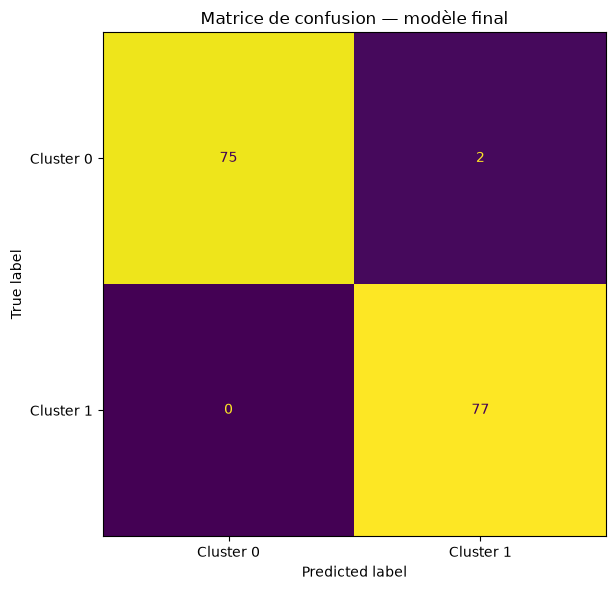

In [41]:
fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=[
        "Cluster 0",
        "Cluster 1",
    ],
    ax=ax,
    colorbar=False,
)

ax.set_title(
    "Matrice de confusion — modèle final"
)

fig.tight_layout()
plt.show()

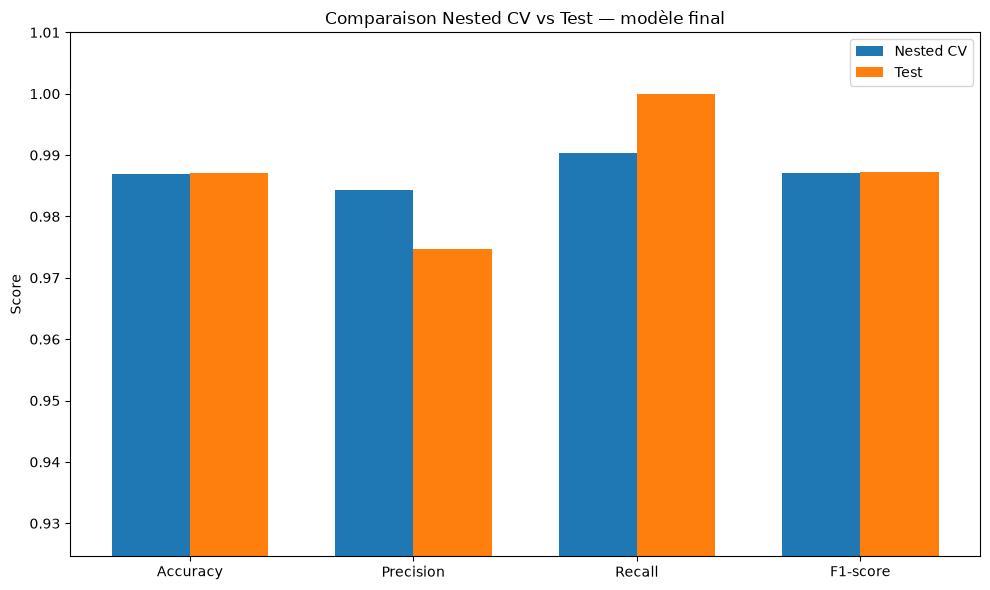

In [42]:
metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
]

cv_values = (
    comparison_final_df[
        "Nested_CV_mean"
    ]
    .to_numpy()
)

test_values = (
    comparison_final_df[
        "Test"
    ]
    .to_numpy()
)

x = np.arange(
    len(metrics_to_plot)
)

width = 0.35

fig, ax = plt.subplots(
    figsize=(10, 6)
)

ax.bar(
    x - width / 2,
    cv_values,
    width,
    label="Nested CV",
)

ax.bar(
    x + width / 2,
    test_values,
    width,
    label="Test",
)

ax.set_xticks(x)
ax.set_xticklabels(metrics_to_plot)

ax.set_ylim(
    max(
        0,
        min(
            cv_values.min(),
            test_values.min(),
        ) - 0.05,
    ),
    1.01,
)

ax.set_ylabel("Score")
ax.set_title(
    "Comparaison Nested CV vs Test — modèle final"
)

ax.legend()

fig.tight_layout()
plt.show()

In [43]:
final_error_summary = pd.DataFrame({
    "error_type": [
        "False Positives",
        "False Negatives",
    ],
    "count": [
        FP,
        FN,
    ],
    "percentage_of_test": [
        FP / len(y_test) * 100,
        FN / len(y_test) * 100,
    ],
})

display(
    final_error_summary.style.format({
        "percentage_of_test": "{:.2f}%",
    })
)

,error_type,count,percentage_of_test
0,False Positives,2,1.30%
1,False Negatives,0,0.00%


## 34. Interprétation du modèle final — coefficients et influence des variables

Le modèle final retenu est une **Logistic Regression** avec :

```text
C = 10.0
Scaler  = NoScaling
Sampler = None
````

Nous allons maintenant examiner comment les différentes caractéristiques cliniques contribuent à la prédiction de `Cluster 1`.

---

## 34.1 Les coefficients de la Logistic Regression

La Logistic Regression calcule une valeur :

$$
z = \beta_0 + \beta_1x_1 + \beta_2x_2 + ... + \beta_nx_n
$$

Cette valeur est ensuite transformée en probabilité avec la fonction sigmoïde.

Chaque variable possède donc un coefficient :

```text
β1
β2
β3
...
βn
```

### Signe du coefficient

Le signe indique la direction de l'association avec la probabilité de `Cluster 1`.

### Coefficient positif

```text
β > 0
```

Lorsque la variable augmente, le modèle tend à augmenter la probabilité de `Cluster 1`.

### Coefficient négatif

```text
β < 0
```

Lorsque la variable augmente, le modèle tend à diminuer la probabilité de `Cluster 1`.

---

## 34.2 Pourquoi le coefficient brut ne suffit pas ?

Nos variables n'ont pas les mêmes unités.

Par exemple :

```text
Glucose                 → dizaines / centaines
Insulin                 → centaines
DiabetesPedigreeFunction → généralement < 3
Age                     → dizaines
```

Un coefficient brut ne permet donc pas de comparer directement l'importance de deux variables.

Exemple conceptuel :

```text
Feature A
coefficient = 0.10
écart-type = 100

Feature B
coefficient = 0.50
écart-type = 0.2
```

Le coefficient de B est plus grand, mais une variation typique de A peut avoir une influence beaucoup plus importante.

Nous calculerons donc également :

$$
\beta_{standardisé} =
\beta \times \sigma
$$

où \(\sigma\) est l'écart-type de la variable dans l'ensemble d'entraînement.

Cela permet d'estimer l'effet associé à une augmentation d'environ **un écart-type** de la variable.

---

## 34.3 Odds et Odds Ratio

La Logistic Regression travaille avec les **log-odds**.

Le coefficient \(\beta\) représente la variation du log-odds associée à une augmentation d'une unité de la variable.

En exponentiant le coefficient :

$$
OR = e^\beta
$$

on obtient l'**Odds Ratio**.

### Interprétation

```text
OR > 1
→ augmentation des odds de Cluster 1

OR = 1
→ aucune variation des odds

OR < 1
→ diminution des odds de Cluster 1
```

Exemple :

```text
OR = 1.20
```

signifie qu'une augmentation d'une unité de la variable multiplie les odds de `Cluster 1` par 1.20, toutes les autres variables restant constantes.

De même :

```text
OR = 0.80
```

signifie que les odds sont multipliées par 0.80, soit une diminution.

> L'Odds Ratio ne représente pas directement une augmentation de 20 % de la probabilité. Il décrit une variation des **odds**, ce qui est différent.

---

## 34.4 Limite d'interprétation

Les coefficients décrivent les relations **apprises par le modèle pour reproduire `Cluster`**.

Ils ne doivent donc pas être interprétés comme :

* des facteurs causaux du diabète ;
* des facteurs de risque médicaux indépendants ;
* des résultats cliniques validés.

Ils indiquent seulement quelles caractéristiques sont les plus utiles au modèle pour distinguer les deux profils créés par le clustering.

---

## 34.5 Ce que nous allons analyser

Pour chaque variable, nous afficherons :

* le coefficient ;
* la valeur absolue du coefficient ;
* l'Odds Ratio ;
* l'écart-type dans `X_train` ;
* le coefficient standardisé ;
* la valeur absolue du coefficient standardisé.

Nous classerons ensuite les variables selon leur coefficient standardisé absolu.

Cette représentation permet de comparer les variables malgré leurs échelles différentes.

In [44]:
final_classifier = (
    final_pipeline
    .named_steps["classifier"]
)

assert isinstance(
    final_classifier,
    LogisticRegression,
)

coefficients = (
    final_classifier
    .coef_[0]
)

intercept = float(
    final_classifier
    .intercept_[0]
)

feature_std = (
    X_train[CLASSIFICATION_FEATURES]
    .std(ddof=0)
)

feature_mean = (
    X_train[CLASSIFICATION_FEATURES]
    .mean()
)

coefficient_df = pd.DataFrame({
    "feature": CLASSIFICATION_FEATURES,
    "coefficient": coefficients,
    "abs_coefficient": np.abs(
        coefficients
    ),
    "train_mean": feature_mean.values,
    "train_std": feature_std.values,
})

coefficient_df["odds_ratio_per_unit"] = (
    np.exp(
        coefficient_df["coefficient"]
    )
)


coefficient_df["standardized_coefficient"] = (
    coefficient_df["coefficient"]
    * coefficient_df["train_std"]
)

coefficient_df["abs_standardized_coefficient"] = (
    np.abs(
        coefficient_df["standardized_coefficient"]
    )
)

coefficient_df["direction"] = np.where(
    coefficient_df["coefficient"] > 0,
    "Vers Cluster 1",
    "Vers Cluster 0",
)

coefficient_df = (
    coefficient_df
    .sort_values(
        by="abs_standardized_coefficient",
        ascending=False,
    )
    .reset_index(drop=True)
)

coefficient_df.insert(
    0,
    "rank",
    np.arange(
        1,
        len(coefficient_df) + 1,
    ),
)

assert len(coefficient_df) == len(
    CLASSIFICATION_FEATURES
)

assert coefficient_df[
    "coefficient"
].notna().all()

assert np.isfinite(
    coefficient_df[
        [
            "coefficient",
            "odds_ratio_per_unit",
            "standardized_coefficient",
        ]
    ].to_numpy()
).all()

display(
    coefficient_df[
        [
            "rank",
            "feature",
            "coefficient",
            "train_std",
            "standardized_coefficient",
            "odds_ratio_per_unit",
            "direction",
        ]
    ].style.format({
        "coefficient": "{:.6f}",
        "train_std": "{:.4f}",
        "standardized_coefficient": "{:.6f}",
        "odds_ratio_per_unit": "{:.4f}",
    })
)

print(
    f"Intercept = {intercept:.6f}"
)

,rank,feature,coefficient,train_std,standardized_coefficient,odds_ratio_per_unit,direction
0,1,Insulin,0.346437,91.9759,31.863878,1.4140,Vers Cluster 1
1,2,BMI,3.670061,6.8138,25.007083,39.2543,Vers Cluster 1
2,3,Glucose,0.785564,29.8813,23.473694,2.1936,Vers Cluster 1
3,4,SkinThickness,2.362214,9.4104,22.229332,10.6144,Vers Cluster 1
4,5,BloodPressure,1.339140,11.7703,15.762045,3.8158,Vers Cluster 1
5,6,DiabetesPedigreeFunction,-4.350732,0.3309,-1.439506,0.0129,Vers Cluster 0
6,7,Age,0.078894,11.7882,0.930010,1.0821,Vers Cluster 1
7,8,Pregnancies,-0.065192,3.4374,-0.224093,0.9369,Vers Cluster 0


Intercept = -425.739978


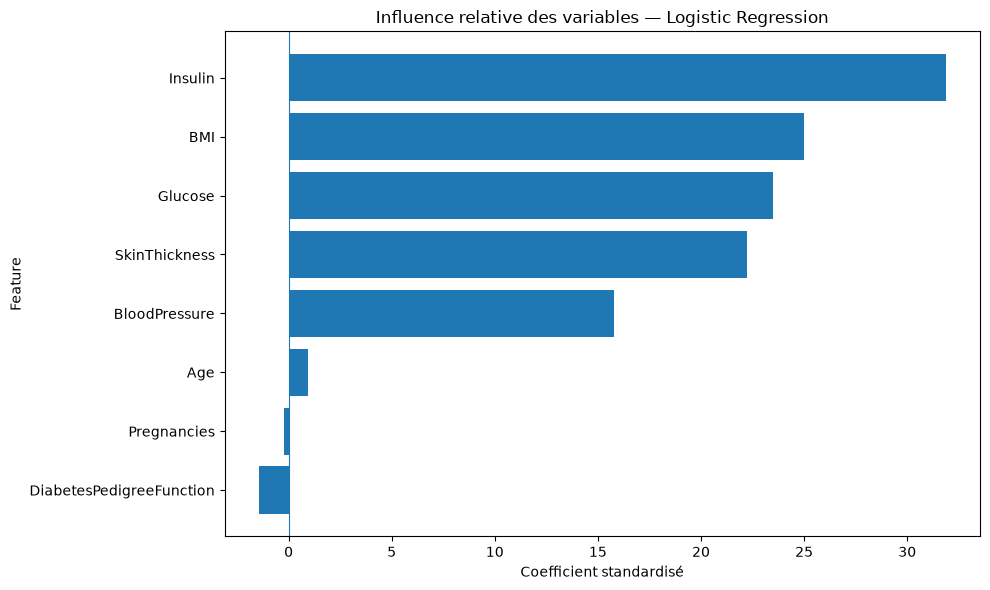

In [45]:
plot_df = (
    coefficient_df
    .sort_values(
        "standardized_coefficient"
    )
)

fig, ax = plt.subplots(
    figsize=(10, 6)
)

ax.barh(
    plot_df["feature"],
    plot_df["standardized_coefficient"],
)

ax.axvline(
    0,
    linewidth=0.8,
)

ax.set_xlabel(
    "Coefficient standardisé"
)

ax.set_ylabel(
    "Feature"
)

ax.set_title(
    "Influence relative des variables — Logistic Regression"
)

fig.tight_layout()
plt.show()

In [46]:
TOP_FEATURES = (
    coefficient_df
    .head(5)
    [
        [
            "feature",
            "standardized_coefficient",
            "odds_ratio_per_unit",
            "direction",
        ]
    ]
    .copy()
)

display(
    TOP_FEATURES.style.format({
        "standardized_coefficient": "{:.6f}",
        "odds_ratio_per_unit": "{:.4f}",
    })
)

,feature,standardized_coefficient,odds_ratio_per_unit,direction
0,Insulin,31.863878,1.4140,Vers Cluster 1
1,BMI,25.007083,39.2543,Vers Cluster 1
2,Glucose,23.473694,2.1936,Vers Cluster 1
3,SkinThickness,22.229332,10.6144,Vers Cluster 1
4,BloodPressure,15.762045,3.8158,Vers Cluster 1


## 35. Analyse des erreurs et des cas limites

L'évaluation finale a montré que le modèle a effectué seulement deux erreurs sur l'ensemble de test :

```text
False Positives = 2
False Negatives = 0
````

Nous allons maintenant examiner ces observations individuellement.

### Pourquoi analyser les erreurs ?

Les métriques globales nous indiquent **combien** d'erreurs le modèle produit.

L'analyse des erreurs nous permet de comprendre **où et pourquoi** elles apparaissent.

Pour chaque observation mal classée, nous allons examiner :

* les caractéristiques cliniques ;
* le cluster réel ;
* la catégorie de risque associée ;
* le cluster prédit ;
* la probabilité prédite de `Cluster 1` ;
* la confiance de la prédiction.

---

## 35.1 Confiance de la prédiction

Pour une Logistic Regression, `predict_proba()` fournit une probabilité pour chaque classe.

Exemple :

```text
Cluster 0 → 0.10
Cluster 1 → 0.90
```

Le modèle est fortement orienté vers `Cluster 1`.

À l'inverse :

```text
Cluster 0 → 0.48
Cluster 1 → 0.52
```

indique une décision beaucoup plus proche de la frontière.

Nous définirons donc :

$$
confidence = \max(P(Cluster 0), P(Cluster 1))
$$

Une confiance proche de :

```text
1.0
```

indique une prédiction plus nette.

Une confiance proche de :

```text
0.5
```

indique une observation proche de la frontière de décision.

---

## 35.2 Marge de décision

Nous examinerons également la distance à la frontière de décision.

Pour Logistic Regression :

```python
decision_function(X)
```

donne le score avant conversion en probabilité.

Conceptuellement :

```text
score < 0
→ Cluster 0

score > 0
→ Cluster 1
```

Un score proche de zéro signifie que l'observation se trouve près de la frontière.

Cela peut aider à identifier les patients difficiles à classer.

---

## 35.3 Que cherchons-nous ?

Nous voulons savoir si les deux erreurs finales :

* sont proches de la frontière ;
* possèdent des caractéristiques atypiques ;
* présentent un profil intermédiaire entre les deux clusters.

Cette analyse est importante pour comprendre les limites du modèle.

> Une observation mal classée n'est pas nécessairement une "mauvaise" observation. Elle peut simplement se trouver dans une zone où les deux profils sont très proches.

In [47]:
y_test_proba_all = (
    final_pipeline
    .predict_proba(X_test)
)

y_test_proba_cluster_1 = (
    y_test_proba_all[:, 1]
)

y_test_proba_cluster_0 = (
    y_test_proba_all[:, 0]
)

y_test_decision = (
    final_pipeline
    .decision_function(X_test)
)

test_analysis_df = X_test.copy()

test_analysis_df["true_cluster"] = (
    y_test.values
)

test_analysis_df["predicted_cluster"] = (
    y_test_pred
)

test_analysis_df["true_risk_category"] = (
    df_clustered
    .loc[
        X_test.index,
        RISK_COLUMN
    ]
    .values
)

test_analysis_df["predicted_risk_category"] = (
    pd.Series(
        y_test_pred,
        index=X_test.index,
    )
    .map({
        0: "Risque Faible",
        1: "Risque Élevé",
    })
    .values
)

test_analysis_df["prob_cluster_0"] = (
    y_test_proba_cluster_0
)

test_analysis_df["prob_cluster_1"] = (
    y_test_proba_cluster_1
)

test_analysis_df["confidence"] = np.maximum(
    y_test_proba_cluster_0,
    y_test_proba_cluster_1,
)

test_analysis_df["decision_score"] = (
    y_test_decision
)

test_analysis_df["correct"] = (
    test_analysis_df["true_cluster"]
    ==
    test_analysis_df["predicted_cluster"]
)

misclassified_df = (
    test_analysis_df[
        ~test_analysis_df["correct"]
    ]
    .sort_values(
        by="confidence",
        ascending=True,
    )
)

uncertain_correct_df = (
    test_analysis_df[
        test_analysis_df["correct"]
    ]
    .sort_values(
        by="confidence",
        ascending=True,
    )
    .head(10)
)

assert len(misclassified_df) == FP + FN

assert (
    misclassified_df["predicted_cluster"]
    !=
    misclassified_df["true_cluster"]
).all()

assert (
    test_analysis_df["confidence"]
    .between(0.5, 1.0)
    .all()
)

display(
    misclassified_df[
        FEATURES
        + [
            "true_cluster",
            "predicted_cluster",
            "true_risk_category",
            "predicted_risk_category",
            "prob_cluster_0",
            "prob_cluster_1",
            "confidence",
            "decision_score",
        ]
    ].style.format({
        "DiabetesPedigreeFunction": "{:.4f}",
        "prob_cluster_0": "{:.4f}",
        "prob_cluster_1": "{:.4f}",
        "confidence": "{:.4f}",
        "decision_score": "{:.4f}",
    })
)

display(
    uncertain_correct_df[
        FEATURES
        + [
            "true_cluster",
            "predicted_cluster",
            "prob_cluster_0",
            "prob_cluster_1",
            "confidence",
            "decision_score",
        ]
    ].style.format({
        "DiabetesPedigreeFunction": "{:.4f}",
        "prob_cluster_0": "{:.4f}",
        "prob_cluster_1": "{:.4f}",
        "confidence": "{:.4f}",
        "decision_score": "{:.4f}",
    })
)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,true_cluster,predicted_cluster,true_risk_category,predicted_risk_category,prob_cluster_0,prob_cluster_1,confidence,decision_score
713,0.000000,134.000000,58.000000,20.000000,291.000000,26.400000,0.3520,21.000000,0,1,Risque Faible,Risque Élevé,0.0938,0.9062,0.9062,2.2682
392,1.000000,131.000000,64.000000,14.000000,415.000000,23.700000,0.3890,21.000000,0,1,Risque Faible,Risque Élevé,0.0000,1.0000,1.0000,26.5959


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,true_cluster,predicted_cluster,prob_cluster_0,prob_cluster_1,confidence,decision_score
519,6.000000,129.000000,90.000000,7.000000,326.000000,19.600000,0.5820,60.000000,0,0,0.6597,0.3403,0.6597,-0.6620
390,1.000000,100.000000,66.000000,29.000000,196.000000,32.000000,0.4440,42.000000,0,0,0.9743,0.0257,0.9743,-3.6358
722,1.000000,149.000000,68.000000,29.000000,127.000000,29.300000,0.3490,42.000000,1,1,0.0157,0.9843,0.9843,4.1351
623,0.000000,94.000000,70.000000,27.000000,115.000000,43.500000,0.3470,21.000000,1,1,0.0052,0.9948,0.9948,5.2576
282,7.000000,133.000000,88.000000,15.000000,155.000000,32.400000,0.2620,37.000000,1,1,0.0026,0.9974,0.9974,5.9482
542,10.000000,90.000000,85.000000,32.000000,90.372090,34.900000,0.8250,56.000000,0,0,0.9977,0.0023,0.9977,-6.0513
766,1.000000,126.000000,60.000000,27.881445,173.505940,30.100000,0.3490,47.000000,0,0,0.9996,0.0004,0.9996,-7.8464
173,1.000000,79.000000,60.000000,42.000000,48.000000,43.500000,0.6780,23.000000,0,0,0.9999,0.0001,0.9999,-9.0428
745,12.000000,100.000000,84.000000,33.000000,105.000000,30.000000,0.4880,46.000000,0,0,0.9999,0.0001,0.9999,-9.5413
467,0.000000,97.000000,64.000000,36.000000,100.000000,36.800000,0.6000,25.000000,0,0,0.9999,0.0001,0.9999,-9.7317


## 36. Analyse complémentaire — 5 features vs 8 features

Le modèle final a été entraîné avec les huit caractéristiques cliniques :

```text
Pregnancies
Glucose
BloodPressure
SkinThickness
Insulin
BMI
DiabetesPedigreeFunction
Age
````

Cependant, le modèle de clustering final avait été construit avec cinq variables :

```text
Glucose
BloodPressure
SkinThickness
Insulin
BMI
```

Cette différence soulève une question intéressante :

> Les trois variables supplémentaires (`Pregnancies`, `DiabetesPedigreeFunction` et `Age`) apportent-elles réellement une information utile pour reproduire les clusters ?

---

## 36.1 Pourquoi comparer les deux sous-ensembles ?

Une feature supplémentaire n'est pas automatiquement bénéfique.

Elle peut :

* apporter une information utile ;
* n'avoir presque aucun effet ;
* ajouter du bruit ;
* augmenter la complexité du modèle sans améliorer ses performances.

Nous allons donc comparer :

### Sous-ensemble A — 5 features

```text
Glucose
BloodPressure
SkinThickness
Insulin
BMI
```

Ce sont les variables utilisées lors du clustering.

### Sous-ensemble B — 8 features

```text
Pregnancies
Glucose
BloodPressure
SkinThickness
Insulin
BMI
DiabetesPedigreeFunction
Age
```

---

## 36.2 Méthode

Nous utiliserons :

* le même `X_train` ;
* le même `y_train` ;
* la même validation croisée stratifiée à 5 folds ;
* la même Logistic Regression ;
* les mêmes hyperparamètres finaux (`C = 10`) ;
* aucun sampling ;
* aucun scaling.

Le seul élément qui change sera le nombre de variables.

Cette approche permet d'isoler l'effet du sous-ensemble de features.

---

## 36.3 Mesure utilisée

Nous comparerons principalement le **F1-score moyen**.

Nous examinerons également :

* Accuracy ;
* Precision ;
* Recall ;
* écart-type du F1-score.

### Interprétation

Si les 8 features obtiennent un meilleur F1 :

```text
8 features > 5 features
```

les trois variables supplémentaires semblent apporter une information utile à la classification.

Si les résultats sont quasiment identiques :

```text
8 features ≈ 5 features
```

les trois variables supplémentaires apportent peu d'information pour reproduire le cluster.

Si les 5 features sont meilleures :

```text
5 features > 8 features
```

les variables supplémentaires peuvent ajouter du bruit dans ce contexte.

> **Important :** cette analyse est complémentaire. Le test set a déjà servi à l'évaluation finale du modèle sélectionné. Nous n'utiliserons donc pas cette comparaison pour modifier rétroactivement le modèle final ou refaire une sélection basée sur le test.

In [ ]:
FEATURES_5 = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
]

FEATURES_8 = CLASSIFICATION_FEATURES.copy()


FEATURE_SUBSETS = {
    "5_features_clustering": FEATURES_5,
    "8_features_clinical": FEATURES_8,
}

FEATURE_TEST_CLASSIFIER = LogisticRegression(
    C=10.0,
    random_state=RANDOM_STATE,
    max_iter=5000,
)


feature_subset_results = []


for subset_name, subset_features in FEATURE_SUBSETS.items():

    print(
        f"\n{'=' * 70}\n"
        f"Feature subset: {subset_name}\n"
        f"{'=' * 70}"
    )

    X_subset_train = X_train[
        subset_features
    ].copy()

    subset_pipeline = build_classification_pipeline(
        scaler="passthrough",
        sampler="passthrough",
        classifier=clone(
            FEATURE_TEST_CLASSIFIER
        ),
    )

    subset_scores = cross_validate(
        estimator=subset_pipeline,
        X=X_subset_train,
        y=y_train,
        cv=CV,
        scoring=SCORING,
        return_train_score=False,
        n_jobs=1,
        error_score="raise",
    )

    feature_subset_results.append({
        "feature_set": subset_name,
        "n_features": len(subset_features),
        "features": ", ".join(
            subset_features
        ),

        "accuracy_mean": subset_scores[
            "test_accuracy"
        ].mean(),

        "accuracy_std": subset_scores[
            "test_accuracy"
        ].std(),

        "precision_mean": subset_scores[
            "test_precision"
        ].mean(),

        "precision_std": subset_scores[
            "test_precision"
        ].std(),

        "recall_mean": subset_scores[
            "test_recall"
        ].mean(),

        "recall_std": subset_scores[
            "test_recall"
        ].std(),

        "f1_mean": subset_scores[
            "test_f1"
        ].mean(),

        "f1_std": subset_scores[
            "test_f1"
        ].std(),
    })

feature_subset_df = (
    pd.DataFrame(
        feature_subset_results
    )
    .sort_values(
        by=[
            "f1_mean",
            "recall_mean",
            "precision_mean",
        ],
        ascending=False,
    )
    .reset_index(drop=True)
)

f1_5 = feature_subset_df.loc[
    feature_subset_df["feature_set"]
    == "5_features_clustering",
    "f1_mean",
].iloc[0]

f1_8 = feature_subset_df.loc[
    feature_subset_df["feature_set"]
    == "8_features_clinical",
    "f1_mean",
].iloc[0]

feature_subset_f1_difference = (
    f1_8 - f1_5
)

assert len(feature_subset_df) == 2

assert (
    feature_subset_df[
        [
            "accuracy_mean",
            "precision_mean",
            "recall_mean",
            "f1_mean",
        ]
    ]
    .apply(
        lambda column: column.between(0, 1)
    )
    .all()
    .all()
)

assert (
    feature_subset_df[
        [
            "accuracy_std",
            "precision_std",
            "recall_std",
            "f1_std",
        ]
    ]
    .ge(0)
    .all()
    .all()
)

display(
    feature_subset_df[
        [
            "feature_set",
            "n_features",
            "features",
            "accuracy_mean",
            "accuracy_std",
            "precision_mean",
            "precision_std",
            "recall_mean",
            "recall_std",
            "f1_mean",
            "f1_std",
        ]
    ].style.format({
        "accuracy_mean": "{:.4f}",
        "accuracy_std": "{:.4f}",
        "precision_mean": "{:.4f}",
        "precision_std": "{:.4f}",
        "recall_mean": "{:.4f}",
        "recall_std": "{:.4f}",
        "f1_mean": "{:.4f}",
        "f1_std": "{:.4f}",
    })
)

print(
    f"\nDifférence F1 (8 features - 5 features) : "
    f"{feature_subset_f1_difference:+.4f}"
)


if feature_subset_f1_difference > 0.005:

    print(
        "Les 8 features apportent une amélioration "
        "notable du F1 moyen."
    )

elif feature_subset_f1_difference < -0.005:

    print(
        "Les 5 features utilisées par le clustering "
        "obtiennent un meilleur F1 moyen."
    )

else:

    print(
        "Les performances des deux sous-ensembles "
        "sont très proches."
    )


Feature subset: 5_features_clustering

Feature subset: 8_features_clinical


,feature_set,n_features,features,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std
0,5_features_clustering,5,"Glucose, BloodPressure, SkinThickness, Insulin, BMI",0.9886,0.0065,0.9874,0.0154,0.9903,0.0129,0.9887,0.0064
1,8_features_clinical,8,"Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, DiabetesPedigreeFunction, Age",0.9886,0.0098,0.9873,0.0156,0.9903,0.0129,0.9887,0.0097



Différence F1 (8 features - 5 features) : -0.0000
Les performances des deux sous-ensembles sont très proches.


## 37. Construction et entraînement du pipeline final

Après la comparaison des différents modèles, des stratégies de preprocessing et des hyperparamètres, le modèle final a été sélectionné à partir de la validation croisée imbriquée.

### Configuration finale retenue

Le modèle sélectionné est une **Logistic Regression** avec :

* les **8 caractéristiques cliniques** ;
* aucun scaling ;
* aucun rééchantillonnage ;
* `C = 10`.

La configuration finale est donc :

```text
8 features
    ↓
Aucun scaling
    ↓
Aucun sampling
    ↓
Logistic Regression
C = 10
    ↓
Prédiction du Cluster
```

### Pourquoi construire un pipeline final ?

Un pipeline regroupe les différentes étapes du traitement et du modèle dans un seul objet.

Cela permet :

* d'éviter d'oublier une étape lors d'une future prédiction ;
* d'utiliser exactement la même transformation entre entraînement et production ;
* de sauvegarder un unique objet réutilisable ;
* de réduire les risques de data leakage ;
* de faciliter l'intégration future avec FastAPI, Streamlit et MLflow.

### Pourquoi entraîner uniquement sur `X_train` ?

Le `test set` reste strictement indépendant.

Il a déjà été utilisé pour l'évaluation finale du modèle sélectionné. Le pipeline final est donc entraîné uniquement sur :

```text
X_train
y_train
```

Le `test set` ne participe ni à l'entraînement ni à une nouvelle sélection du modèle.

Le modèle construit ici correspond à la configuration finale déjà validée précédemment.


In [52]:
assert CLASSIFICATION_FEATURES == FEATURES

assert FINAL_MODEL_NAME == "LogisticRegression"
assert FINAL_PREPROCESSING["scaler"] == "NoScaling"
assert FINAL_PREPROCESSING["sampler"] == "None"
assert FINAL_BEST_PARAMS["classifier__C"] == 10.0

final_pipeline = build_classification_pipeline(
    classifier=CLASSIFIERS[FINAL_MODEL_NAME],
    scaler=SCALERS[FINAL_PREPROCESSING["scaler"]],
    sampler=SAMPLERS[FINAL_PREPROCESSING["sampler"]],
)

final_pipeline.set_params(**FINAL_BEST_PARAMS)

X_train_final = X_train.loc[:, CLASSIFICATION_FEATURES].copy()
y_train_final = y_train.copy()

assert X_train_final.shape[1] == 8
assert list(X_train_final.columns) == CLASSIFICATION_FEATURES
assert len(X_train_final) == len(y_train_final)

assert not X_train_final.isna().any().any()
assert np.isfinite(X_train_final.to_numpy()).all()

final_pipeline.fit(
    X_train_final,
    y_train_final,
)

final_classifier = final_pipeline.named_steps["classifier"]

print("=" * 70)
print("PIPELINE FINAL — ENTRAÎNEMENT")
print("=" * 70)

print(f"Modèle              : {FINAL_MODEL_NAME}")
print(f"Nombre de features  : {X_train_final.shape[1]}")
print(f"Features             : {CLASSIFICATION_FEATURES}")
print(f"Scaling              : {FINAL_PREPROCESSING['scaler']}")
print(f"Sampling             : {FINAL_PREPROCESSING['sampler']}")
print(f"Hyperparamètres      : {FINAL_BEST_PARAMS}")

print("\nClasses apprises :")
print(final_classifier.classes_)

print(f"\nNombre d'observations utilisées : {len(X_train_final)}")
print(f"Nombre de coefficients         : {final_classifier.coef_.shape[1]}")

print("\nPipeline final :")
print(final_pipeline)

PIPELINE FINAL — ENTRAÎNEMENT
Modèle              : LogisticRegression
Nombre de features  : 8
Features             : ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
Scaling              : NoScaling
Sampling             : None
Hyperparamètres      : {'classifier__C': 10.0}

Classes apprises :
[0 1]

Nombre d'observations utilisées : 614
Nombre de coefficients         : 8

Pipeline final :
Pipeline(steps=[('scaler', 'passthrough'), ('sampler', 'passthrough'),
                ('classifier',
                 LogisticRegression(C=10.0, max_iter=5000, random_state=42))])


# 🧬 Conclusion — Classification supervisée

## Bilan général

Cette étape a permis de construire et d'évaluer un système de **classification supervisée capable de reproduire l'appartenance aux clusters obtenus précédemment par le clustering K-Means**.

L'objectif n'était donc pas de diagnostiquer directement le diabète, mais d'apprendre à partir des caractéristiques cliniques la décision de regroupement produite par le modèle non supervisé.

La variable `risk_category` a volontairement été exclue des variables explicatives afin d'éviter toute **fuite d'information (*target leakage*)**.

---

## Préparation des données

Le modèle a été construit à partir des huit caractéristiques cliniques suivantes :

```text
Pregnancies
Glucose
BloodPressure
SkinThickness
Insulin
BMI
DiabetesPedigreeFunction
Age
```

Les données ont été séparées en :

* **80 % pour l'entraînement** : 614 observations ;
* **20 % pour le test final** : 154 observations.

La séparation a été stratifiée afin de conserver la proportion des deux classes dans les deux ensembles.

La distribution des classes étant quasiment équilibrée, les stratégies de rééchantillonnage telles que **Random Oversampling, Random Undersampling et SMOTE** n'ont pas apporté d'amélioration significative et n'ont donc pas été retenues dans le pipeline final.

---

## Comparaison des modèles

Plusieurs familles de modèles ont été comparées :

```text
Logistic Regression
KNN
SVM
Decision Tree
Random Forest
Extra Trees
HistGradientBoosting
```

Différentes stratégies de scaling et de rééchantillonnage ont également été testées.

La validation croisée à 5 folds, réalisée uniquement sur l'ensemble d'entraînement, a permis de comparer les configurations de manière plus robuste.

Les trois meilleures familles après cette étape étaient :

1. **Logistic Regression**
2. **SVM**
3. **Extra Trees**

Une validation croisée imbriquée a ensuite permis de comparer les meilleurs candidats en limitant le risque de surestimation des performances liée à la sélection des hyperparamètres.

La **Logistic Regression** a obtenu les meilleures performances globales et la meilleure stabilité.

---

## Modèle final

Le modèle final retenu est :

```text
Logistic Regression
C = 10
Scaling = aucun
Sampling = aucun
Features = 8
```

Le pipeline final est donc :

```text
8 caractéristiques cliniques
        ↓
Aucun scaling
        ↓
Aucun rééchantillonnage
        ↓
Logistic Regression (C = 10)
        ↓
Cluster 0 / Cluster 1
```

Ce choix est particulièrement intéressant car une **Logistic Regression simple**, correctement configurée, a surpassé les modèles plus complexes testés dans ce contexte.

---

## Évaluation finale sur le test set

Le test set, conservé indépendant pendant le processus de sélection, a donné les performances suivantes :

| Métrique  |   Résultat |
| --------- | ---------: |
| Accuracy  | **0.9870** |
| Precision | **0.9747** |
| Recall    | **1.0000** |
| F1-score  | **0.9872** |
| ROC-AUC   | **0.9983** |

La matrice de confusion finale est :

```text
[[75, 2],
 [ 0,77]]
```

Cela correspond à :

* **75 vrais négatifs** ;
* **2 faux positifs** ;
* **0 faux négatif** ;
* **77 vrais positifs**.

Le modèle n'a donc commis **aucun faux négatif sur le test set**, tandis que seulement deux observations de la classe `Cluster 0` ont été prédites comme appartenant au `Cluster 1`.

---

## Analyse des variables

L'analyse des coefficients de la Logistic Regression montre que plusieurs variables contribuent fortement à la séparation entre les deux clusters.

Après prise en compte de l'échelle des variables, les principales contributions observées concernent notamment :

```text
Insulin
BMI
Glucose
SkinThickness
BloodPressure
```

Ces coefficients doivent cependant être interprétés comme des **associations permettant de reproduire les clusters**.

Ils ne représentent pas des relations causales et ne doivent pas être interprétés comme une preuve qu'une variable provoque le diabète ou augmente directement un risque médical.

---

## Comparaison de 5 features et 8 features

Une analyse complémentaire a comparé :

### 5 features utilisées par le clustering

```text
Glucose
BloodPressure
SkinThickness
Insulin
BMI
```

### 8 features cliniques

```text
Pregnancies
Glucose
BloodPressure
SkinThickness
Insulin
BMI
DiabetesPedigreeFunction
Age
```

Les deux configurations ont obtenu exactement le même F1 moyen à l'arrondi :

```text
5 features → F1 = 0.9887
8 features → F1 = 0.9887
```

Les trois variables supplémentaires n'apportent donc pas d'amélioration mesurable dans cette expérience pour reproduire les clusters.

Malgré cela, les **8 features sont conservées dans le modèle final**, car cette analyse est complémentaire et ne doit pas entraîner une modification rétroactive du modèle après son évaluation finale sur le test set.

---

## Interprétation finale

Les résultats montrent qu'il est possible d'apprendre efficacement la structure produite par le clustering à l'aide d'un modèle supervisé très simple.

La combinaison finale :

```text
8 features
+ Logistic Regression
+ C = 10
```

permet d'obtenir une excellente reproduction des deux profils identifiés par le clustering, avec :

```text
Accuracy ≈ 98.7 %
F1-score ≈ 98.7 %
ROC-AUC ≈ 99.8 %
```

La validation croisée et la validation croisée imbriquée montrent également que ces performances sont globalement stables sur différentes partitions des données.

---

## Limites

Cette classification présente néanmoins plusieurs limites importantes.

Le modèle apprend à reproduire des **clusters définis par un algorithme de clustering**, et non une vérité clinique indépendante.

La catégorie :

```text
Cluster 0 → Risque Faible
Cluster 1 → Risque Élevé
```

provient de la règle d'interprétation définie dans le projet et ne constitue pas un diagnostic médical.

Les performances très élevées doivent donc être interprétées comme une **bonne capacité à reproduire les profils générés par le pipeline GlucoProfile**, et non comme une preuve d'une capacité équivalente à diagnostiquer le diabète sur de nouveaux patients dans un contexte clinique réel.

Une validation sur des données externes, indépendantes et représentatives serait nécessaire avant toute utilisation médicale réelle.

---

## Suite du projet

Le notebook de classification a ainsi produit les éléments nécessaires à l'intégration du modèle dans l'architecture globale de **GlucoProfile**.

La suite du projet consiste à industrialiser ce modèle à travers :

```text
classification.py
        ↓
Sauvegarde du modèle
        ↓
MLflow Tracking
        ↓
MLflow Model Registry
        ↓
FastAPI
        ↓
Streamlit
        ↓
Airflow — réentraînement
        ↓
Docker / Docker Compose
```

Le système complet pourra ainsi évoluer d'une expérimentation réalisée dans un notebook vers un **pipeline Machine Learning reproductible, traçable et déployable**.
